In [261]:
import pandas as pd
import numpy as np
import scipy.spatial as sp
import scipy.cluster.hierarchy as hc
from sklearn.decomposition import PCA
from sklearn import preprocessing
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
import seaborn as sns
import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib import colors as mcolors
import matplotlib.patches as patches
import itertools
from adjustText import adjust_text

# look at the SDS behavior analogs

In [13]:
p_df = pd.read_csv(f"data/results_hamd-1_-logp_0.01.csv",index_col=0)
cols = p_df.columns
idx = p_df.index

In [121]:
questions = [3,7,10]
corr_dfs = {}
corr_ms = {}
corr_tri_ms = {}

for q in questions:
    corr_dfs[q] = pd.read_csv(f"data/results_hamd-{q}_r.csv", header=None)
    corr_dfs[q].index = idx
    corr_dfs[q].columns = cols
    corr_ms[q] = np.array(corr_dfs[q].values)
    corr_ms[q][np.isnan(corr_ms[q] )] = 0
    corr_tri_ms[q] = np.tril(corr_dfs[q].values,k=-1)
    

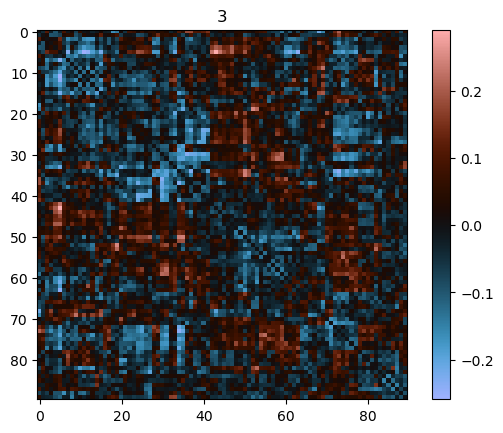

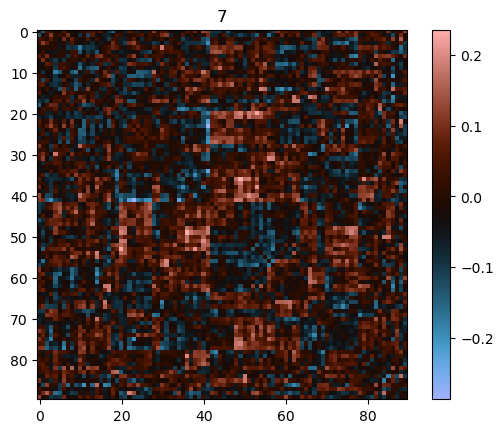

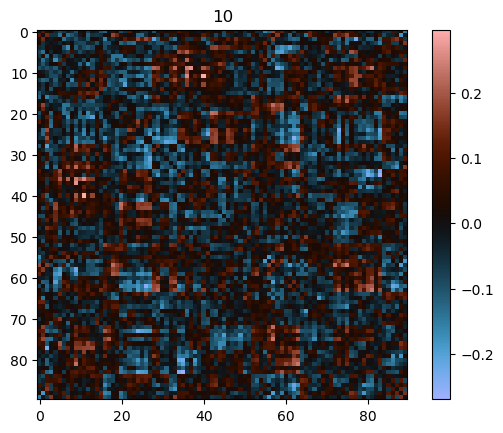

In [98]:
for q in questions:
    f = plt.figure()
    plt.title(q)
    plt.imshow(corr_ms[q],cmap='berlin')
    plt.colorbar()

In [99]:
for q in questions:
    print(f"{q}: {np.linalg.norm(corr_ms[q])}")

3: 7.056820613155604
7: 6.317769788230619
10: 6.99198903502732


In [100]:
for x,y in itertools.combinations(questions, 2):
    print(f'{x} and {y}: {np.linalg.norm(corr_ms[x]-corr_ms[y])}')

3 and 7: 7.533419115163732
3 and 10: 8.416110944395214
7 and 10: 8.137546028539832


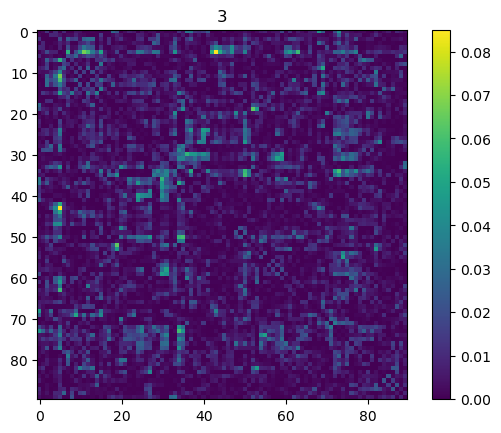

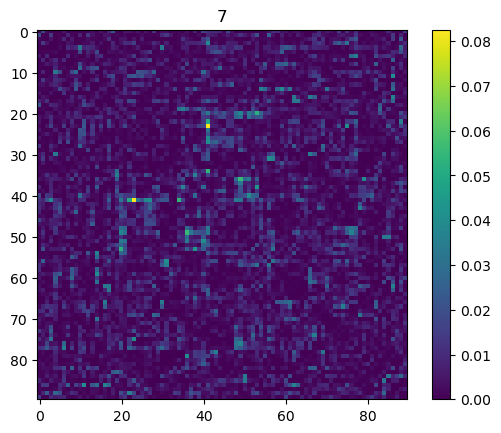

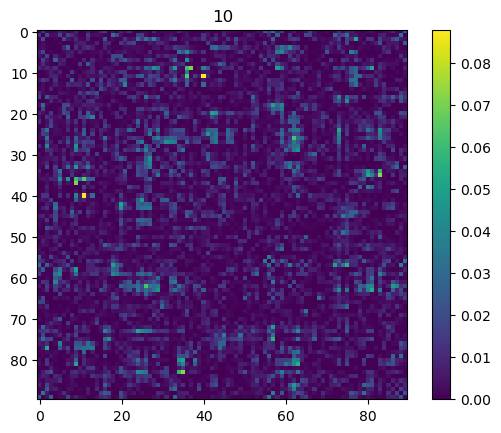

In [125]:
corr2_ms = {}
for q in questions:
    corr2_ms[q] = np.multiply(corr_ms[q],corr_ms[q])
    f = plt.figure()
    plt.imshow(corr2_ms[q])
    plt.colorbar()
    plt.title(q)

In [102]:
for q in questions:
    print(f"{q}: {np.linalg.norm(corr2_ms[q])}")

3: 0.9487636820040446
7: 0.7553572686197441
10: 0.9390541344458838


In [103]:
for x,y in itertools.combinations(questions, 2):
    print(f'{x} and {y}: {np.linalg.norm(corr2_ms[x]-corr2_ms[y])}')

3 and 7: 0.9346559377170162
3 and 10: 1.0308169882084581
7 and 10: 0.9429543908123171


In [108]:
shuffle_norms = {}
num_shuffles = 100

for x,y in itertools.combinations(questions, 2):
    shuffle_norms[f"{x} {y}"] = []
    for i in range(num_shuffles):
        m1 = corr2_ms[x].copy()
        n = m1.shape[0]
        idx = np.random.permutation(n)
        m1 = m1[idx,:]
        m1 = m1[:,idx]
        
        m2 = corr2_ms[y].copy()
        n = m2.shape[0]
        idx = np.random.permutation(n)
        m2 = m2[idx,:]
        m2 = m2[:,idx]

        shuffle_norms[f"{x} {y}"].append(np.linalg.norm(m2-m1))

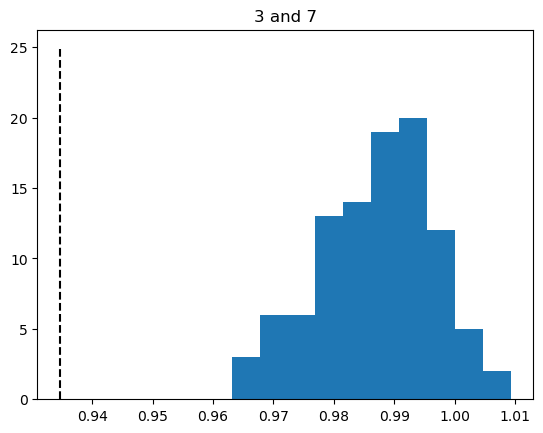

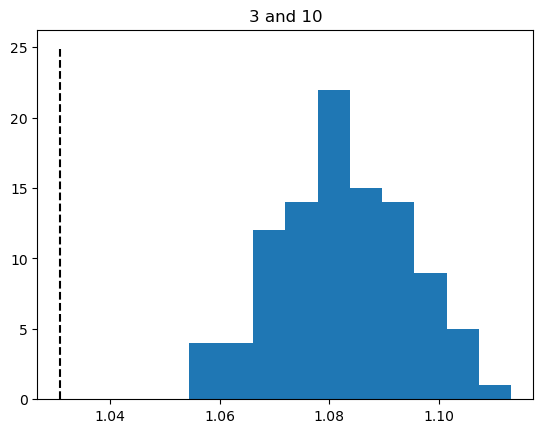

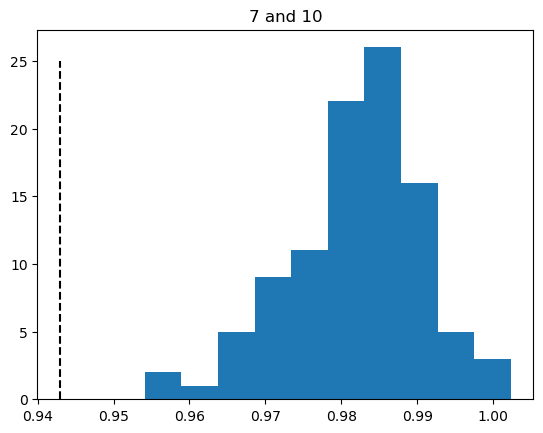

In [112]:
for x,y in itertools.combinations(questions, 2):
    norm = np.linalg.norm(corr2_ms[x]-corr2_ms[y])
    f = plt.figure()
    plt.title(f"{x} and {y}")
    plt.hist(shuffle_norms[f"{x} {y}"])
    plt.vlines(x=norm,ymin=0,ymax=25,colors="black",linestyles='dashed');

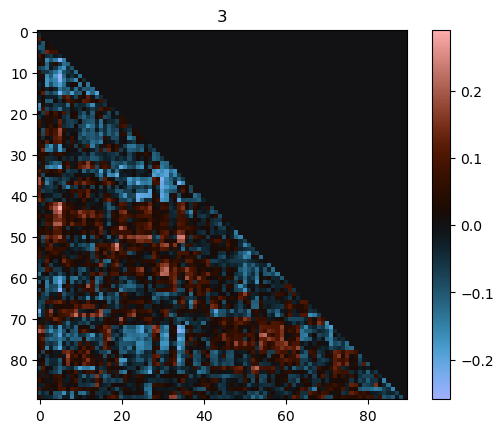

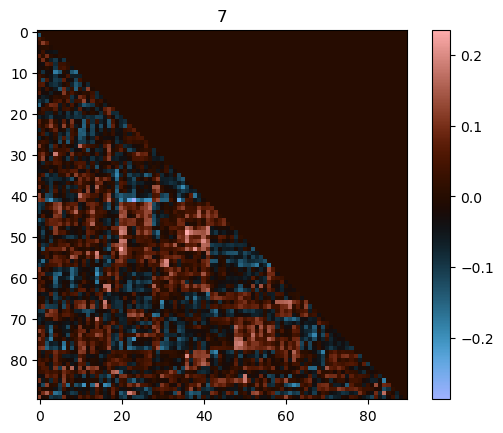

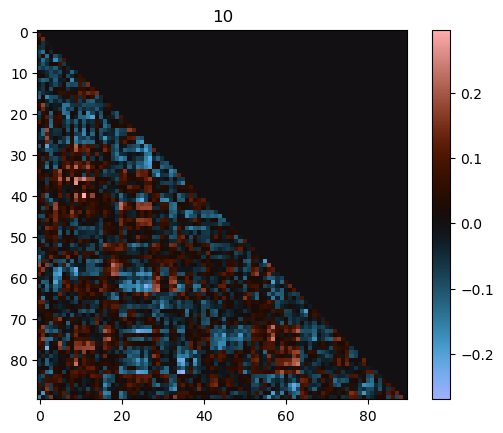

In [122]:
for q in questions:
    f = plt.figure()
    plt.title(q)
    plt.imshow(corr_tri_ms[q],cmap='berlin')
    plt.colorbar()

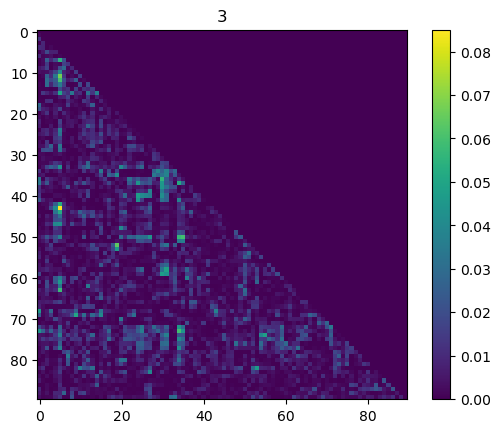

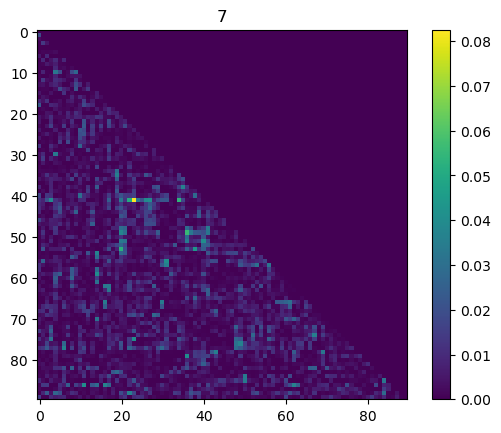

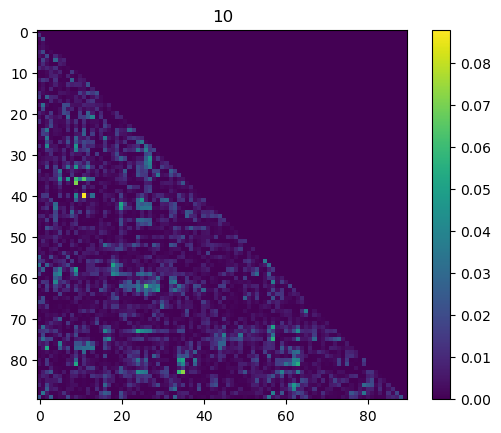

In [165]:
corr2_tri_ms = {}
for q in questions:
    corr2_tri_ms[q] = np.multiply(corr_tri_ms[q],corr_tri_ms[q])
    f = plt.figure()
    plt.imshow(corr2_tri_ms[q])
    plt.colorbar()
    plt.title(q)

In [166]:
corr2_tri_vs = {}
corr_tri_vs = {}
for q in questions:
    corr2_tri_vs[q] = corr2_tri_ms[q][np.tril_indices(len(corr2_tri_ms[q]),k=-1)]
    corr_tri_vs[q] = corr_tri_ms[q][np.tril_indices(len(corr2_tri_ms[q]),k=-1)]


In [167]:
for x,y in itertools.combinations(questions, 2):
    angle = np.arccos((np.dot(corr2_tri_vs[x],corr2_tri_vs[y]))/(np.linalg.norm(corr2_tri_vs[x])*np.linalg.norm(corr2_tri_vs[y])))
    angle = angle*180/np.pi
    print(f"{x} and {y}: {angle}")

3 and 7: 65.37909161451617
3 and 10: 66.18868808587615
7 and 10: 66.60821504478002


In [139]:
shuffle_angles = {}
num_shuffles = 100

for x,y in itertools.combinations(questions, 2):
    shuffle_angles[f"{x} {y}"] = []
    for i in range(num_shuffles):
        m1 = corr2_tri_vs[x].copy()
        n = m1.shape[0]
        idx = np.random.permutation(n)
        m1 = m1[idx]
        
        m2 = corr2_tri_vs[y].copy()
        n = m2.shape[0]
        idx = np.random.permutation(n)
        m2 = m2[idx]

        angle = np.arccos((np.dot(m1,m2))/(np.linalg.norm(m1)*np.linalg.norm(m2)))
        angle = angle*180/np.pi

        shuffle_angles[f"{x} {y}"].append(angle)

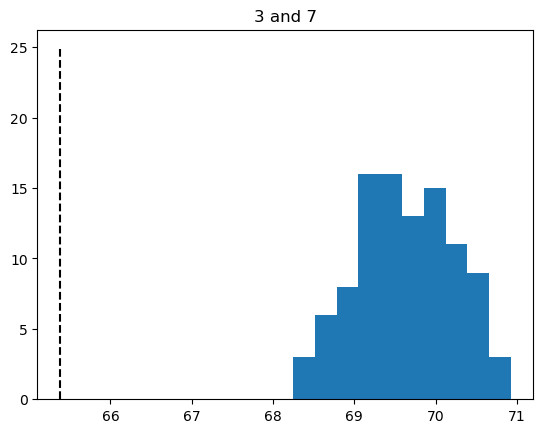

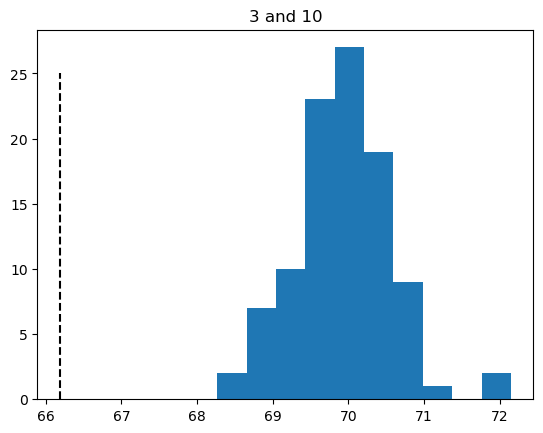

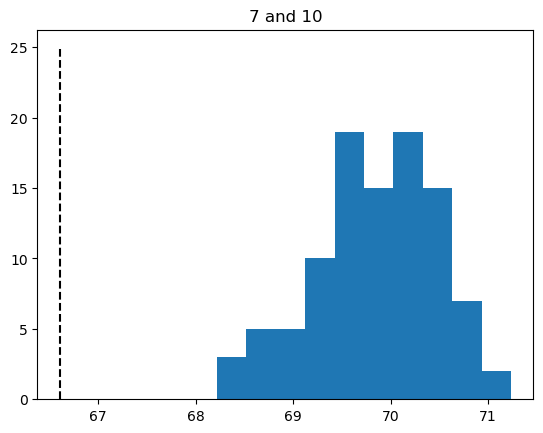

In [140]:
for x,y in itertools.combinations(questions, 2):
    angle = np.arccos((np.dot(corr2_tri_vs[x],corr2_tri_vs[y]))/(np.linalg.norm(corr2_tri_vs[x])*np.linalg.norm(corr2_tri_vs[y])))
    angle = angle*180/np.pi

    f = plt.figure()
    plt.title(f"{x} and {y}")
    plt.hist(shuffle_angles[f"{x} {y}"])
    plt.vlines(x=angle,ymin=0,ymax=25,colors="black",linestyles='dashed');

# look at all rankings

In [2]:
p_df = pd.read_csv(f"data/results_hamd-1_-logp_0.01.csv",index_col=0)
cols = p_df.columns
idx = p_df.index

In [4]:

corr_dfs = {}
corr_ms = {}
corr_tri_ms = {}
corr2_tri_ms = {}
corr2_ms = {}
corr2_tri_vs = {}
corr_tri_vs = {}
    
for q in range(1,18):
    corr_dfs[q] = pd.read_csv(f"data/results_hamd-{q}_r.csv", header=None)
    corr_dfs[q].index = idx
    corr_dfs[q].columns = cols
    corr_ms[q] = np.array(corr_dfs[q].values)
    corr_ms[q][np.isnan(corr_ms[q] )] = 0
    corr2_ms[q] = np.multiply(corr_ms[q],corr_ms[q])
    corr_tri_ms[q] = np.tril(corr_dfs[q].values,k=-1)
    corr2_tri_ms[q] = np.tril(corr2_ms[q],k=-1)
    corr2_tri_vs[q] = corr2_tri_ms[q][np.tril_indices(len(corr2_tri_ms[q]),k=-1)]
    corr_tri_vs[q] = corr_tri_ms[q][np.tril_indices(len(corr2_tri_ms[q]),k=-1)]


In [714]:
x,y = corr2_tri_ms[1].nonzero()
vs_feature_labels = [f"{cols[xx]},{cols[yy]}" for xx,yy in zip(x,y)]

In [717]:
vs_feature_labels[:10]

['Precentral_R,Precentral_L',
 'Frontal_Sup_L,Precentral_L',
 'Frontal_Sup_L,Precentral_R',
 'Frontal_Sup_R,Precentral_L',
 'Frontal_Sup_R,Precentral_R',
 'Frontal_Sup_R,Frontal_Sup_L',
 'Frontal_Sup_Orb_L,Precentral_L',
 'Frontal_Sup_Orb_L,Precentral_R',
 'Frontal_Sup_Orb_L,Frontal_Sup_L',
 'Frontal_Sup_Orb_L,Frontal_Sup_R']

In [719]:
corr2_tri_ms[1]

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.04836728, 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.0146102 , 0.00103005, 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.00624005, 0.00529611, 0.00031447, ..., 0.        , 0.        ,
        0.        ],
       [0.01008944, 0.00198851, 0.00743489, ..., 0.02126779, 0.        ,
        0.        ],
       [0.00849735, 0.01749841, 0.00628021, ..., 0.00169011, 0.03852042,
        0.        ]])

In [721]:
corr2_tri_vs[1][:10]

array([4.83672759e-02, 1.46102013e-02, 1.03004880e-03, 4.00283870e-03,
       4.11282576e-03, 1.23836316e-06, 1.96938307e-03, 5.16149867e-04,
       6.30390802e-04, 7.96253774e-04])

In [5]:
for q in range(1,18):
    print(f"{q}: {np.linalg.norm(corr_ms[q])}")

1: 6.246154085322634
2: 6.52957344196795
3: 7.056820613155604
4: 6.480497553066502
5: 6.70496112857087
6: 6.925392854937381
7: 6.317769788230619
8: 8.275664157031544
9: 7.013436888656119
10: 6.99198903502732
11: 6.6675921321460905
12: 6.170112322542692
13: 6.68030165274403
14: 6.7101289862549836
15: 6.473401480043923
16: 6.162893133949912
17: 6.109225358438413


In [6]:
for q in range(1,18):
    print(f"{q}: {np.linalg.norm(corr2_ms[q])}")

1: 0.7409814549678067
2: 0.8353550247836214
3: 0.9487636820040446
4: 0.7980685336504365
5: 0.9055939144080194
6: 0.9249134713084849
7: 0.7553572686197441
8: 1.302405715534668
9: 0.9491318223460675
10: 0.9390541344458838
11: 0.858516421747182
12: 0.7169339310415349
13: 0.8355208072392546
14: 0.8501981520502145
15: 0.7948826953384377
16: 0.7426712560698573
17: 0.7338156896856266


In [8]:
norms = np.zeros((17,17))

for (i,x),(j,y) in itertools.combinations(enumerate(range(1,18)), 2):
    norms[i,j] = np.linalg.norm(corr_tri_vs[x]-corr_tri_vs[y])

In [63]:
base_cmap = mpl.colormaps['cividis']
colors = base_cmap(np.linspace(0,1,500))
colors[0,:] = mcolors.to_rgba("black")
custom_cmap = mcolors.ListedColormap(colors)

In [40]:
norms[norms.nonzero()].min()

4.41313893455794

In [41]:
labels = np.linspace(1,17,int(18/2),dtype=int)
ticks = np.linspace(0,16,int(18/2),dtype=int)

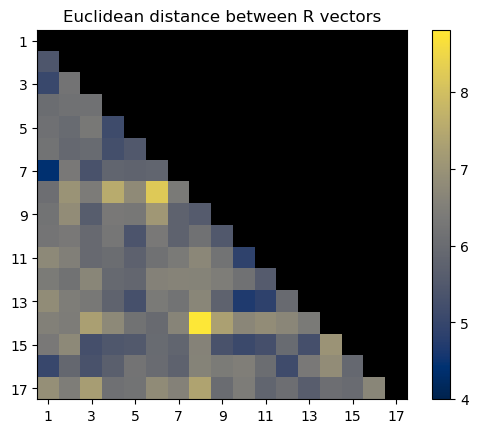

In [64]:
plt.imshow(norms.transpose(),cmap=custom_cmap,vmin=4)
plt.xticks(ticks,labels)
plt.yticks(ticks,labels)
plt.title('Euclidean distance between R vectors')
plt.colorbar()

Text(0.5, 1.0, 'Euclidean distance between R vectors')

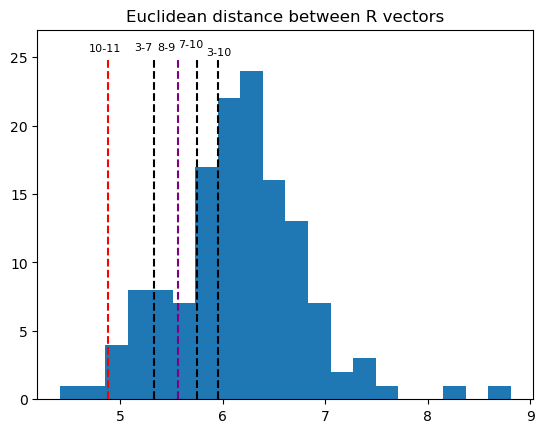

In [65]:
plt.hist(norms[norms.nonzero()],bins=20)
plt.vlines(x=[norms[2,6],norms[2,9],norms[6,9]],ymin=0,ymax=25,colors="black",linestyles='dashed');
plt.vlines(x=[norms[9,10]],ymin=0,ymax=25,colors="red",linestyles='dashed');
plt.vlines(x=[norms[7,8]],ymin=0,ymax=25,colors="purple",linestyles='dashed');
texts = []
texts.append(plt.text(x=norms[2,6]-0.2,y=25.3,s="3-7",fontsize=8))
texts.append(plt.text(x=norms[2,9]-0.2,y=25.3,s="3-10",fontsize=8))
texts.append(plt.text(x=norms[6,9]-0.2,y=25.3,s="7-10",fontsize=8))
texts.append(plt.text(x=norms[9,10]-0.2,y=25.3,s="10-11",fontsize=8))
texts.append(plt.text(x=norms[7,8]-0.2,y=25.3,s="8-9",fontsize=8))
adjust_text(texts)
plt.ylim([0,27])
plt.title("Euclidean distance between R vectors")

In [47]:
r2norms = np.zeros((17,17))

for (i,x),(j,y) in itertools.combinations(enumerate(range(1,18)), 2):
    r2norms[i,j] = np.linalg.norm(corr2_tri_vs[x]-corr2_tri_vs[y])

In [49]:
r2norms[r2norms.nonzero()].min()

0.540041654537913

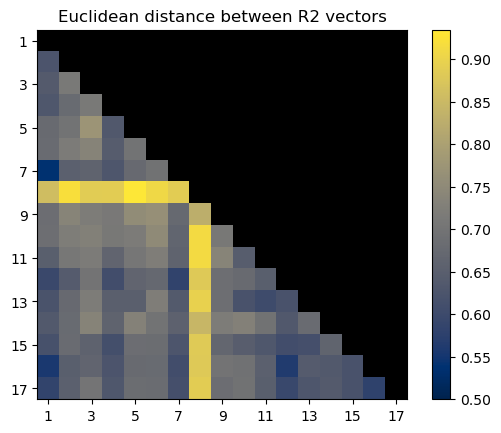

In [50]:
plt.imshow(r2norms.transpose(),cmap=custom_cmap,vmin=0.5)
plt.xticks(ticks,labels)
plt.yticks(ticks,labels)
plt.title('Euclidean distance between R2 vectors')
plt.colorbar()

Text(0.5, 1.0, 'Euclidean distance between R2 vectors')

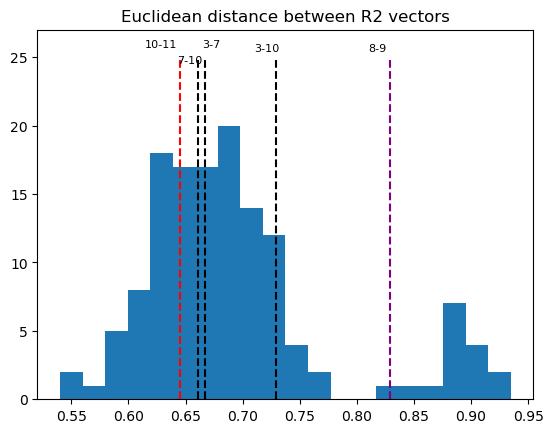

In [66]:
plt.hist(r2norms[r2norms.nonzero()],bins=20)
plt.vlines(x=[r2norms[2,6],r2norms[2,9],r2norms[6,9]],ymin=0,ymax=25,colors="black",linestyles='dashed');
plt.vlines(x=[r2norms[9,10]],ymin=0,ymax=25,colors="red",linestyles='dashed');
plt.vlines(x=[r2norms[7,8]],ymin=0,ymax=25,colors="purple",linestyles='dashed');
texts = []
texts.append(plt.text(x=r2norms[2,6]-0.02,y=25.3,s="3-7",fontsize=8))
texts.append(plt.text(x=r2norms[2,9]-0.02,y=25.3,s="3-10",fontsize=8))
texts.append(plt.text(x=r2norms[6,9]-0.02,y=25.3,s="7-10",fontsize=8))
texts.append(plt.text(x=r2norms[9,10]-0.02,y=25.3,s="10-11",fontsize=8))
texts.append(plt.text(x=r2norms[7,8]-0.02,y=25.3,s="8-9",fontsize=8))
adjust_text(texts)
plt.ylim([0,27])
plt.title("Euclidean distance between R2 vectors")

In [54]:
angle = np.zeros((17,17))

for (i,x),(j,y) in itertools.combinations(enumerate(range(1,18)), 2):
    angle[i,j] = np.arccos((np.dot(corr2_tri_vs[x],corr2_tri_vs[y]))/(np.linalg.norm(corr2_tri_vs[x])*np.linalg.norm(corr2_tri_vs[y])))
    angle[i,j] = angle[i,j]*180/np.pi

In [55]:
angle[angle.nonzero()].min()

58.945760249105895

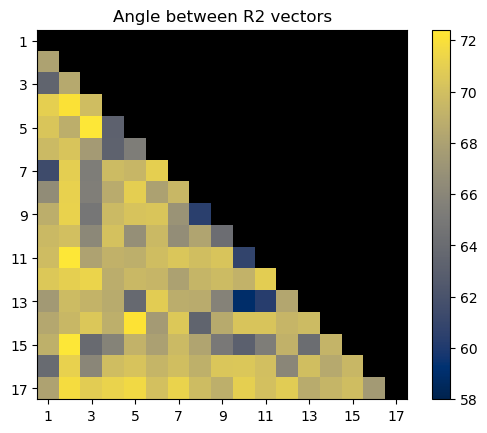

In [56]:
plt.imshow(angle.transpose(),cmap=custom_cmap,vmin=58)
plt.xticks(ticks,labels)
plt.yticks(ticks,labels)
plt.title('Angle between R2 vectors')
plt.colorbar()

Text(0.5, 1.0, 'Angle between R2 vectors')

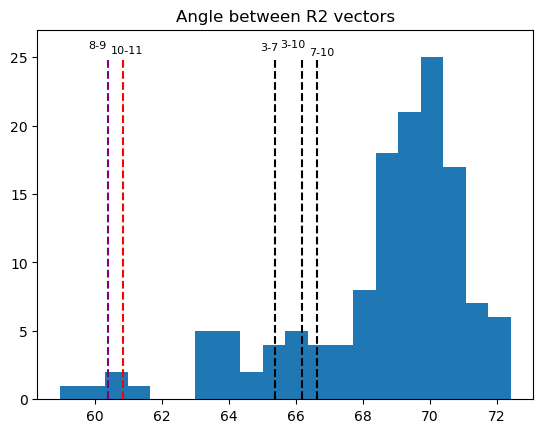

In [57]:
plt.hist(angle[angle.nonzero()],bins=20)
plt.vlines(x=[angle[2,6],angle[2,9],angle[6,9]],ymin=0,ymax=25,colors="black",linestyles='dashed');
plt.vlines(x=[angle[9,10]],ymin=0,ymax=25,colors="red",linestyles='dashed');
plt.vlines(x=[angle[7,8]],ymin=0,ymax=25,colors="purple",linestyles='dashed');
texts = []
texts.append(plt.text(x=angle[2,6]-0.5,y=25.3,s="3-7",fontsize=8))
texts.append(plt.text(x=angle[2,9]-0.5,y=25.3,s="3-10",fontsize=8))
texts.append(plt.text(x=angle[6,9]-0.5,y=25.3,s="7-10",fontsize=8))
texts.append(plt.text(x=angle[9,10]-0.5,y=25.3,s="10-11",fontsize=8))
texts.append(plt.text(x=angle[7,8]-0.5,y=25.3,s="8-9",fontsize=8))
adjust_text(texts)
plt.ylim([0,27])
plt.title("Angle between R2 vectors")

In [58]:
rangle = np.zeros((17,17))

for (i,x),(j,y) in itertools.combinations(enumerate(range(1,18)), 2):
    rangle[i,j] = np.arccos((np.dot(corr_tri_vs[x],corr_tri_vs[y]))/(np.linalg.norm(corr_tri_vs[x])*np.linalg.norm(corr_tri_vs[y])))
    rangle[i,j] = rangle[i,j]*180/np.pi

In [59]:
rangle[rangle.nonzero()].min()

57.84127060397003

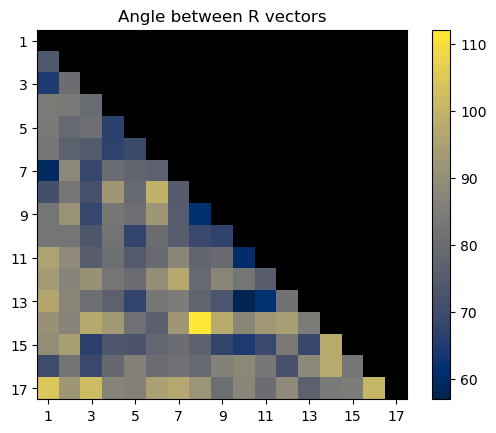

In [67]:
plt.imshow(rangle.transpose(),cmap=custom_cmap,vmin=57)
plt.xticks(ticks,labels)
plt.yticks(ticks,labels)
plt.title('Angle between R vectors')
plt.colorbar()

Text(0.5, 1.0, 'Angle between R vectors')

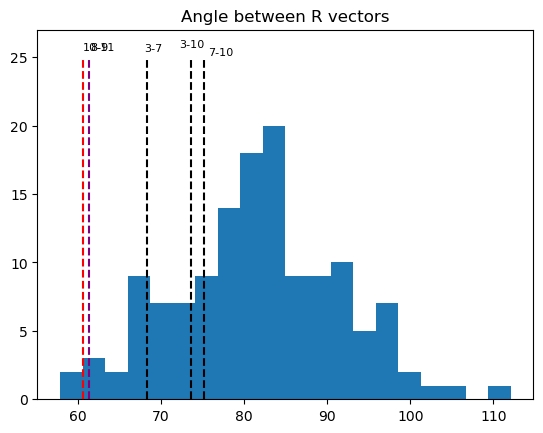

In [236]:
plt.hist(rangle[rangle.nonzero()],bins=20)
plt.vlines(x=[rangle[2,6],rangle[2,9],rangle[6,9]],ymin=0,ymax=25,colors="black",linestyles='dashed');
plt.vlines(x=[rangle[9,10]],ymin=0,ymax=25,colors="red",linestyles='dashed');
plt.vlines(x=[rangle[7,8]],ymin=0,ymax=25,colors="purple",linestyles='dashed');
texts = []
texts.append(plt.text(x=rangle[2,6]-0.5,y=25.3,s="3-7",fontsize=8))
texts.append(plt.text(x=rangle[2,9]-0.5,y=25.3,s="3-10",fontsize=8))
texts.append(plt.text(x=rangle[6,9]-0.5,y=25.3,s="7-10",fontsize=8))
texts.append(plt.text(x=rangle[9,10]-0.5,y=25.3,s="10-11",fontsize=8))
texts.append(plt.text(x=rangle[7,8]-0.5,y=25.3,s="8-9",fontsize=8))
adjust_text(texts)
plt.ylim([0,27])
plt.title("Angle between R vectors")

# try clustering

In [69]:
angle.shape == rangle.shape == norms.shape == r2norms.shape

True

In [68]:
for i in range(17):
    for j in range(17):
        if i==j:
            r2norms[i,j] = 0
            norms[i,j] = 0
            rangle[i,j] = 0
            angle[i,j] = 0
        if i>j:
            r2norms[i,j] = r2norms[j,i]
            norms[i,j] = norms[j,i]
            rangle[i,j] = rangle[j,i]
            angle[i,j] = angle[j,i]

In [71]:
base_cmap = mpl.colormaps['rocket_r']
colors = base_cmap(np.linspace(0,1,256))
colors[0,:] = mcolors.to_rgba("lightgray")
custom_cmap = mcolors.ListedColormap(colors)

In [74]:
r2norms[r2norms.nonzero()].min()

0.540041654537913

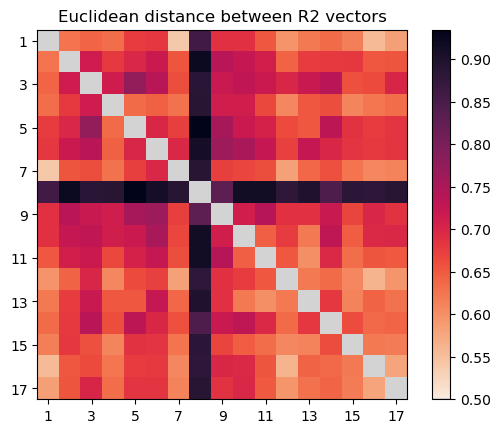

In [111]:
plt.imshow(r2norms,vmin=0.5,cmap=custom_cmap)
plt.xticks(ticks,labels)
plt.yticks(ticks,labels)
plt.title('Euclidean distance between R2 vectors')
plt.colorbar()

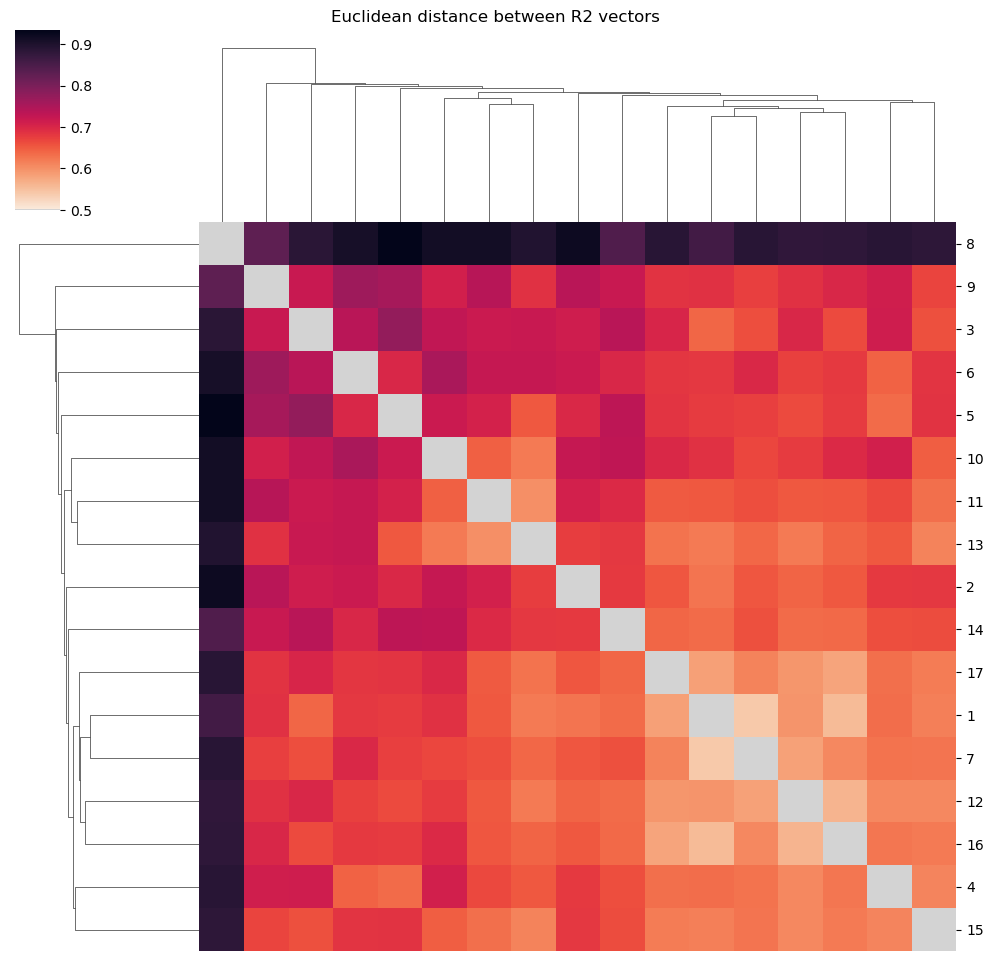

In [109]:
linkage = hc.linkage(sp.distance.squareform(r2norms), method='average')
ax = sns.clustermap(r2norms, row_linkage=linkage, col_linkage=linkage,
                                 cmap=custom_cmap,vmin=0.5)
ax.ax_heatmap.set_xticks([])
ax.ax_heatmap.set_yticks([x + 0.5 for x in list(range(17))],[x + 1 for x in ax.dendrogram_col.reordered_ind]);
ax.ax_heatmap.tick_params("y",rotation=0)
ax.fig.suptitle("Euclidean distance between R2 vectors")
ax.fig.subplots_adjust(top=0.95)
cbar_pos = (0.02, 0.78, 0.045, 0.18) 
ax.ax_cbar.set_position(cbar_pos)

In [81]:
norms[norms.nonzero()].min()

4.41313893455794

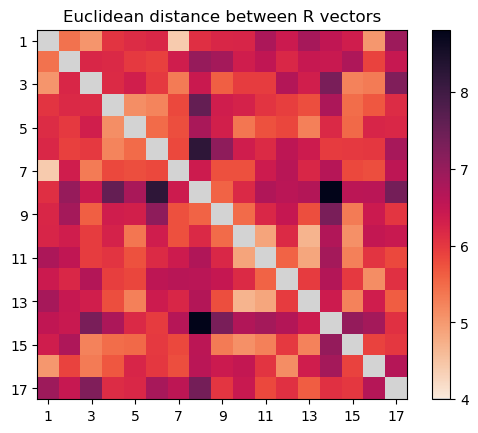

In [112]:
plt.imshow(norms,vmin=4,cmap=custom_cmap)
plt.xticks(ticks,labels)
plt.yticks(ticks,labels)
plt.title('Euclidean distance between R vectors')
plt.colorbar()

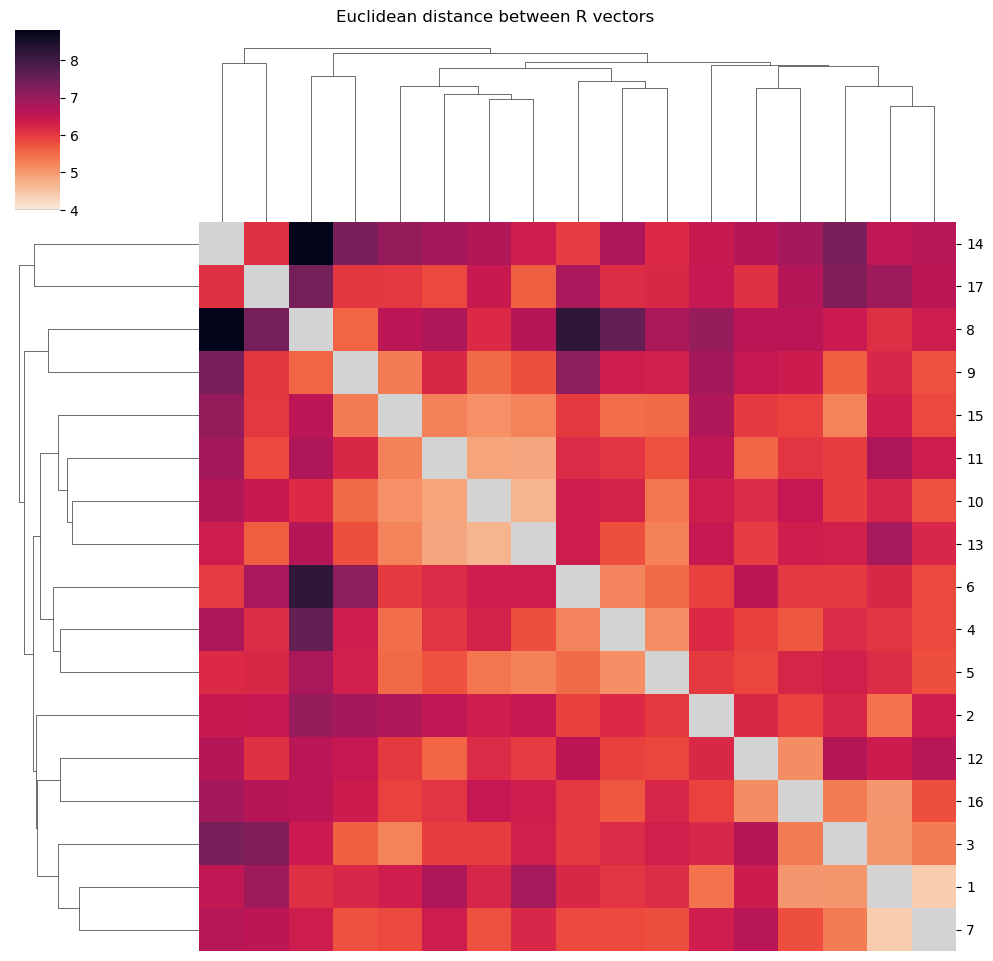

In [108]:
linkage = hc.linkage(sp.distance.squareform(norms), method='average')
ax = sns.clustermap(norms, row_linkage=linkage, col_linkage=linkage,
                                 cmap=custom_cmap,vmin=4)
ax.ax_heatmap.set_xticks([])
ax.ax_heatmap.set_yticks([x + 0.5 for x in list(range(17))],[x + 1 for x in ax.dendrogram_col.reordered_ind]);
ax.ax_heatmap.tick_params("y",rotation=0)
ax.fig.suptitle("Euclidean distance between R vectors")
ax.fig.subplots_adjust(top=0.95)
cbar_pos = (0.02, 0.78, 0.045, 0.18) 
ax.ax_cbar.set_position(cbar_pos)


In [119]:
angle[angle.nonzero()].min()

58.945760249105895

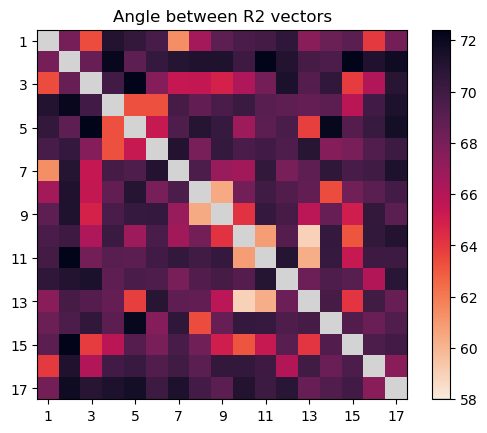

In [113]:
plt.imshow(angle,vmin=58,cmap=custom_cmap)
plt.xticks(ticks,labels)
plt.yticks(ticks,labels)
plt.title('Angle between R2 vectors')
plt.colorbar()

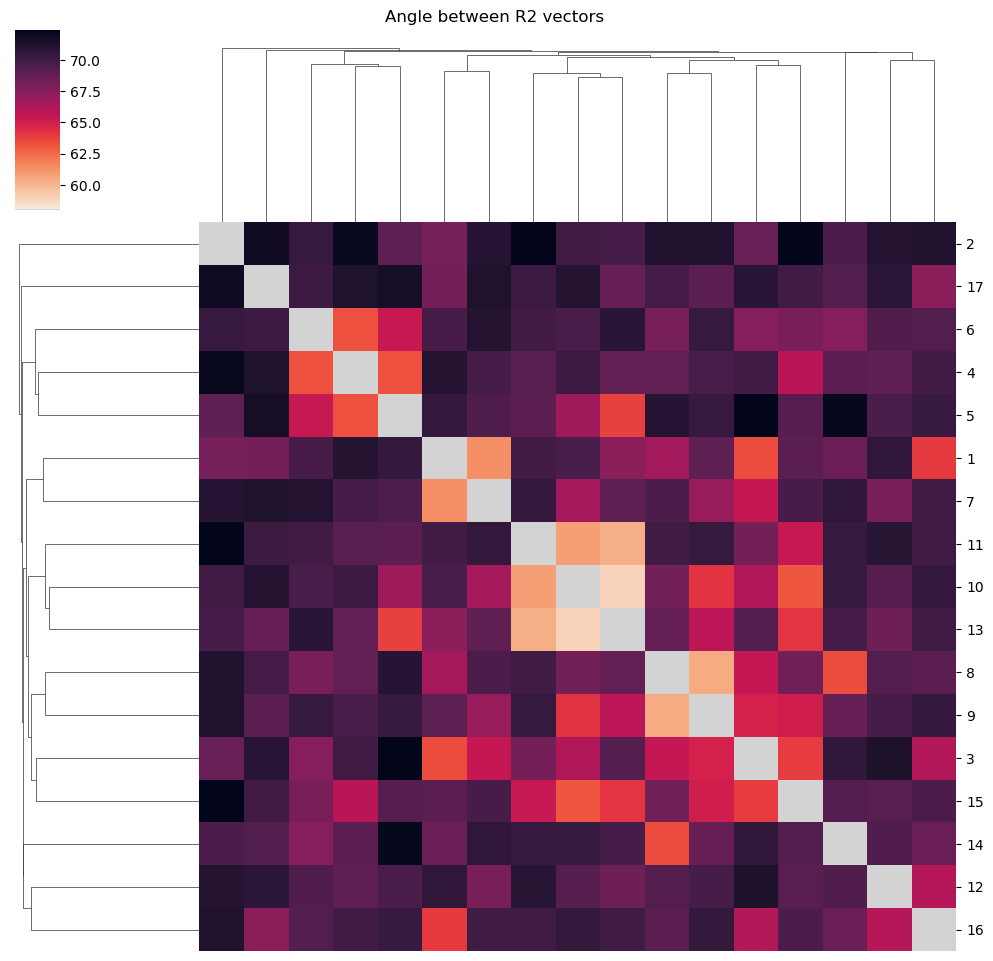

In [114]:
linkage = hc.linkage(sp.distance.squareform(angle), method='average')
ax = sns.clustermap(angle, row_linkage=linkage, col_linkage=linkage,
                                 cmap=custom_cmap,vmin=58)
ax.ax_heatmap.set_xticks([])
ax.ax_heatmap.set_yticks([x + 0.5 for x in list(range(17))],[x + 1 for x in ax.dendrogram_col.reordered_ind]);
ax.ax_heatmap.tick_params("y",rotation=0)
ax.fig.suptitle("Angle between R2 vectors")
ax.fig.subplots_adjust(top=0.95)
cbar_pos = (0.02, 0.78, 0.045, 0.18) 
ax.ax_cbar.set_position(cbar_pos)

In [116]:
rangle[rangle.nonzero()].min()

57.84127060397003

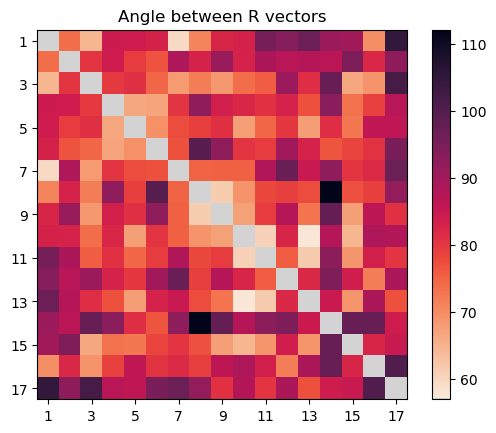

In [122]:
plt.imshow(rangle,vmin=57,cmap=custom_cmap)
plt.xticks(ticks,labels)
plt.yticks(ticks,labels)
plt.title('Angle between R vectors')
plt.colorbar()

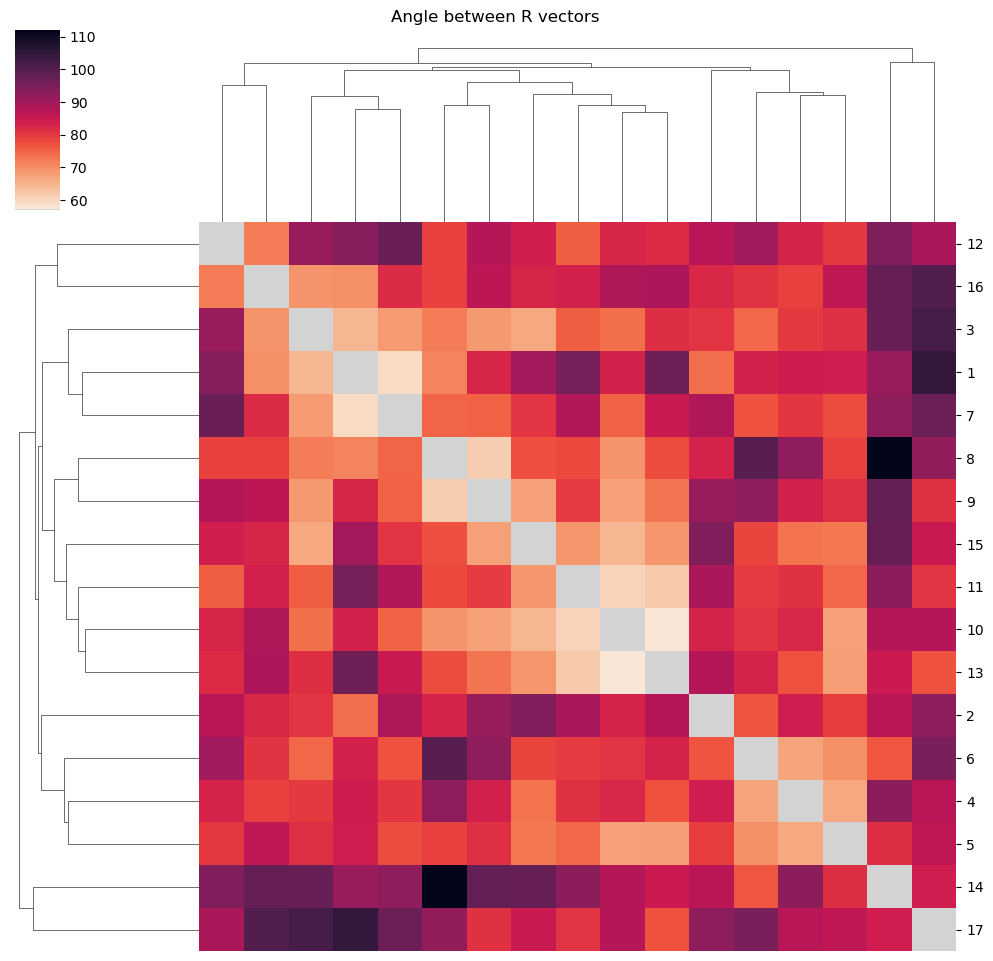

In [121]:
linkage = hc.linkage(sp.distance.squareform(rangle), method='average')
ax = sns.clustermap(rangle, row_linkage=linkage, col_linkage=linkage,
                                 cmap=custom_cmap,vmin=57)
ax.ax_heatmap.set_xticks([])
ax.ax_heatmap.set_yticks([x + 0.5 for x in list(range(17))],[x + 1 for x in ax.dendrogram_col.reordered_ind]);
ax.ax_heatmap.tick_params("y",rotation=0)
ax.fig.suptitle("Angle between R vectors")
ax.fig.subplots_adjust(top=0.95)
cbar_pos = (0.02, 0.78, 0.045, 0.18) 
ax.ax_cbar.set_position(cbar_pos)

# explore pca of r2s

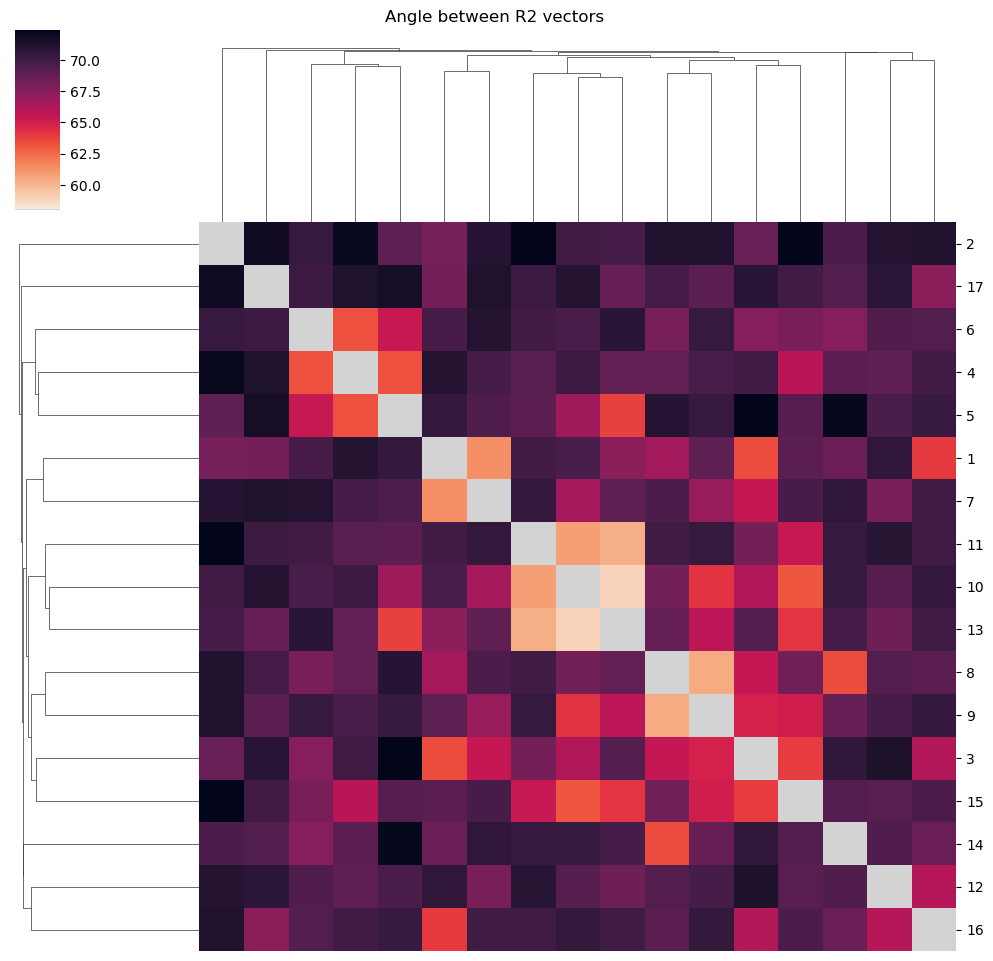

In [188]:
linkage = hc.linkage(sp.distance.squareform(angle), method='average')
clustermap = sns.clustermap(angle, row_linkage=linkage, col_linkage=linkage,
                                 cmap=custom_cmap,vmin=58)
clustermap.ax_heatmap.set_xticks([])
clustermap.ax_heatmap.set_yticks([x + 0.5 for x in list(range(17))],[x + 1 for x in clustermap.dendrogram_col.reordered_ind]);
clustermap.ax_heatmap.tick_params("y",rotation=0)
clustermap.fig.suptitle("Angle between R2 vectors")
clustermap.fig.subplots_adjust(top=0.95)
cbar_pos = (0.02, 0.78, 0.045, 0.18) 
clustermap.ax_cbar.set_position(cbar_pos)

In [191]:
h = 66

ridx = clustermap.dendrogram_col.reordered_ind
clusters = hc.cut_tree(linkage,height=h)
clusters = [i[0] for i in clusters]
current_cluster = 0
idx_start = [0]
idx_end = []
cluster_order = []

xtick_idx = []
xtick_label = []
for i,x in enumerate(ridx):
    if clusters[x]==current_cluster:
        continue
    else:
        idx_end.append(i)
        idx_start.append(i)
        current_cluster = clusters[x]
        cluster_order.append(current_cluster)
        #print(f'new cluster {current_cluster} for {x} in position {i}')
idx_end.append(i)

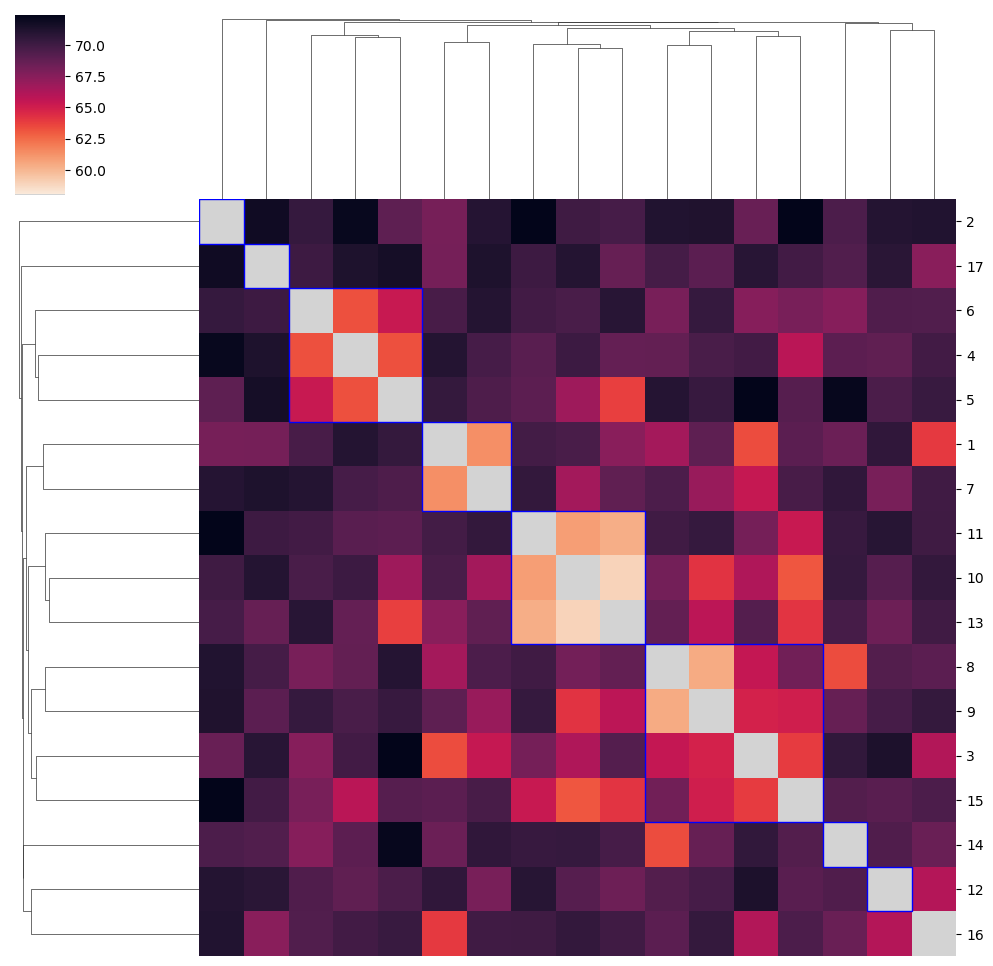

In [192]:
clustermap = sns.clustermap(angle, row_linkage=linkage, col_linkage=linkage,
                                 cmap=custom_cmap,vmin=58, rasterized=True)
ax = clustermap.ax_heatmap
for c in range(max(clusters)+1):
    c_idx = cluster_order[c]
    start = idx_start[c+1]
    end = idx_end[c+1]
    #print(f'{c_idx} {start} {end}')
    rect = patches.Rectangle((start,start), end-start, end-start, linewidth=1,edgecolor='b', facecolor='none')
    ax.add_patch(rect)
    #veh_ax.text(end+3,(start+end)/2,f'{c_idx}', fontsize=20)

#ax.set_xticks(xtick_idx,xtick_label)
ax.set_yticks([]);

ax.set_xticks([])
ax.set_yticks([x + 0.5 for x in list(range(17))],[x + 1 for x in clustermap.dendrogram_col.reordered_ind]);
ax.tick_params("y",rotation=0)

#cmap[groupvalue].fig.suptitle(groupvalue);
#plt.show()
#plt.tight_layout()
#plt.savefig(f'figures/hierarchical-clustering/socialdefeat-{groupvalue}.rois.png',bbox_inches='tight')
#plt.savefig(f'figures/hierarchical-clustering/socialdefeat-{groupvalue}.rois.svg',bbox_inches='tight')

In [226]:
cluster_order

[1, 8, 3, 0, 4, 2, 6, 5, 7]

In [227]:
clusters

[0, 1, 2, 3, 3, 3, 0, 2, 2, 4, 4, 5, 4, 6, 2, 7, 8]

In [228]:
scores

array([ 2, 17,  6,  4,  5,  1,  7, 11, 10, 13,  8,  9,  3, 15, 14, 12, 16])

In [1138]:
clusters_of_interest = [4,0,2] # 3
#scores = np.array([r+1 for r in ridx])
scores = np.array(list(range(1,18)))
scores_of_interest = scores[[True if c in clusters_of_interest else False for c in clusters]]
score_clusters = np.array([c for c in clusters if c in clusters_of_interest])

In [1181]:
clusters_of_interest = np.array(range(1,18))
scores_of_interest = clusters_of_interest
score_clusters = clusters_of_interest

In [1182]:
for c in clusters_of_interest:
    cluster_scores = [s for i,s in enumerate(scores_of_interest) if score_clusters[i]==c]
    print(f"{c}: {cluster_scores}")

1: [1]
2: [2]
3: [3]
4: [4]
5: [5]
6: [6]
7: [7]
8: [8]
9: [9]
10: [10]
11: [11]
12: [12]
13: [13]
14: [14]
15: [15]
16: [16]
17: [17]


In [1183]:
scores_of_interest

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17])

In [1184]:
score_clusters

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17])

In [1185]:
data = np.zeros((len(scores_of_interest),corr2_tri_vs[1].shape[0]))
for i in range(data.shape[0]):
    data[i,:] = corr_tri_vs[scores_of_interest[i]]
scaled_data = preprocessing.normalize(data, norm='l2',axis=1)

In [1186]:
(scaled_data**2).sum(axis=1)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [1187]:
pca = PCA()
pca.fit(scaled_data)
embedding = pca.transform(scaled_data)
embedding.shape

(17, 17)

(0.0, 0.2)

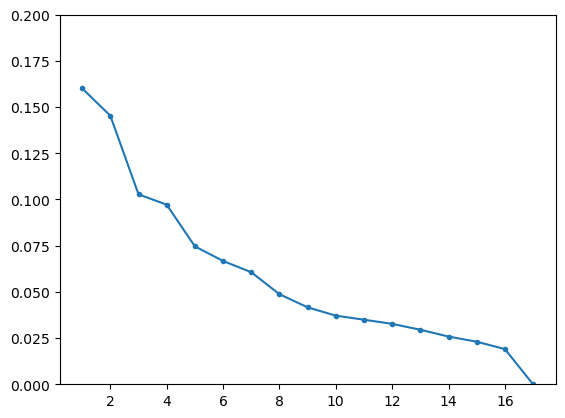

In [1189]:
plt.plot(range(1,embedding.shape[1]+1),pca.explained_variance_ratio_,'.-')
plt.ylim([0, 0.2])

In [1190]:
cmap = plt.colormaps['viridis']
color_vector = cmap(np.linspace(0,1, len(clusters_of_interest)))
color_dict = {}
for i,c in enumerate(clusters_of_interest):
    color_dict[c]=color_vector[i,:]

In [1149]:
scores_of_interest

array([ 1,  3,  7,  8,  9, 10, 11, 13, 15])

In [1150]:
score_clusters

array([0, 2, 0, 2, 2, 4, 4, 4, 2], dtype=int64)

Text(30.972222222222214, 0.5, 'pc2')

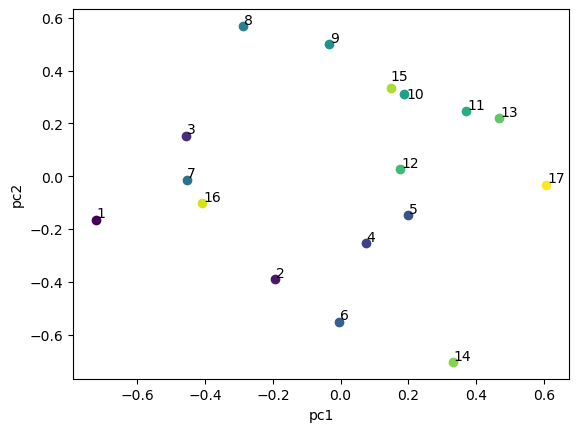

In [1191]:
f, ax = plt.subplots()
for c in clusters_of_interest:
    sc = plt.scatter(embedding[score_clusters==c,0],embedding[score_clusters==c,1],color=color_dict[c],label=c)
texts = []
for i,s in enumerate(scores_of_interest):
    texts.append(plt.text(embedding[i,0]+0.0005,embedding[i,1]+0.0005,s))
adjust_text(texts)    
plt.xlabel("pc1")
plt.ylabel("pc2")

Text(30.972222222222214, 0.5, 'pc4')

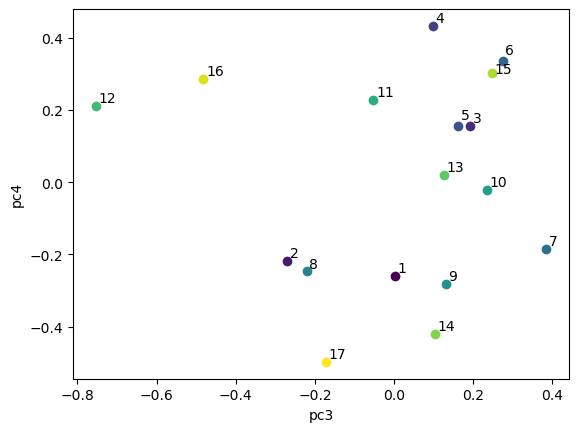

In [1192]:
f, ax = plt.subplots()
for c in clusters_of_interest:
    sc = plt.scatter(embedding[score_clusters==c,2],embedding[score_clusters==c,3],color=color_dict[c],label=c)
texts = []
for i,s in enumerate(scores_of_interest):
    texts.append(plt.text(embedding[i,2]+0.005,embedding[i,3]+0.005,s))
adjust_text(texts)
plt.xlabel("pc3")
plt.ylabel("pc4")

Text(30.972222222222214, 0.5, 'pc6')

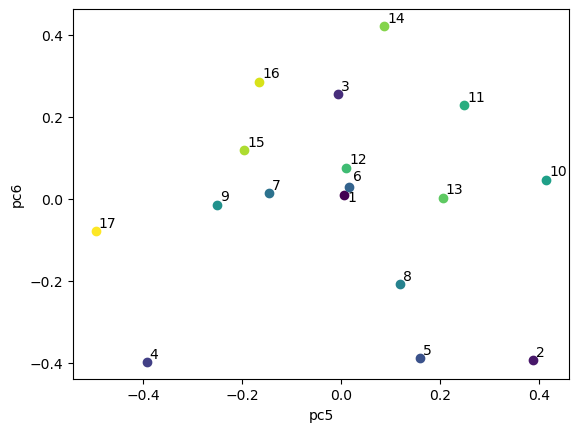

In [1193]:
f, ax = plt.subplots()
for c in clusters_of_interest:
    sc = plt.scatter(embedding[score_clusters==c,4],embedding[score_clusters==c,5],color=color_dict[c],label=c)
texts = []
for i,s in enumerate(scores_of_interest):
    texts.append(plt.text(embedding[i,4]+0.005,embedding[i,5]+0.005,s))
adjust_text(texts)
plt.xlabel("pc5")
plt.ylabel("pc6")

Text(30.972222222222214, 0.5, 'pc8')

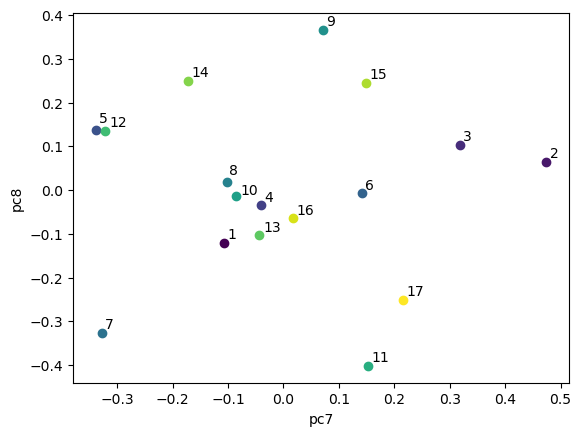

In [1194]:
f, ax = plt.subplots()
for c in clusters_of_interest:
    sc = plt.scatter(embedding[score_clusters==c,6],embedding[score_clusters==c,7],color=color_dict[c],label=c)
texts = []
for i,s in enumerate(scores_of_interest):
    texts.append(plt.text(embedding[i,6]+0.005,embedding[i,7]+0.005,s))
adjust_text(texts)
plt.xlabel("pc7")
plt.ylabel("pc8")

Text(30.972222222222214, 0.5, 'pc10')

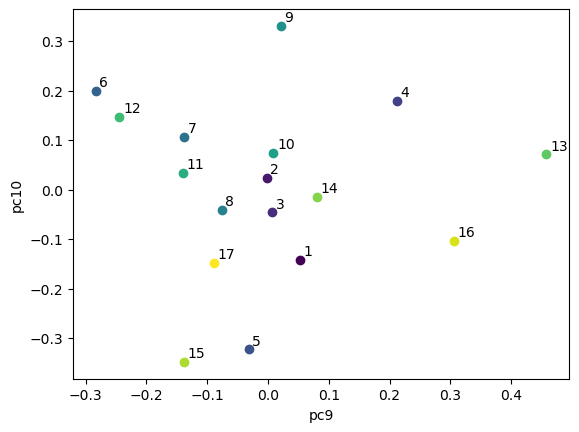

In [1195]:
f, ax = plt.subplots()
for c in clusters_of_interest:
    sc = plt.scatter(embedding[score_clusters==c,8],embedding[score_clusters==c,9],color=color_dict[c],label=c)
texts = []
for i,s in enumerate(scores_of_interest):
    texts.append(plt.text(embedding[i,8]+0.005,embedding[i,9]+0.005,s))
adjust_text(texts)
plt.xlabel("pc9")
plt.ylabel("pc10")

In [1196]:
pca_comp_df = pd.DataFrame(np.transpose(pca.components_),index = vs_feature_labels,columns = range(1,embedding.shape[1]+1))

pca_comp_df

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
"Precentral_R,Precentral_L",0.049859,0.025461,0.015208,0.010794,0.008049,-0.012128,0.017823,0.029001,-0.010961,0.011567,-0.017909,-0.001045,-0.008029,-0.017490,0.005477,-0.011907,0.147210
"Frontal_Sup_L,Precentral_L",-0.028744,-0.004082,-0.002238,-0.010045,0.005072,0.016459,0.010262,0.003618,0.013279,0.003489,-0.010051,0.018526,0.013540,0.021895,0.002646,-0.008207,0.022848
"Frontal_Sup_L,Precentral_R",0.025226,0.011453,0.011739,-0.015222,-0.003271,-0.012526,0.014300,0.018637,-0.016740,-0.007374,-0.017611,0.008788,0.012104,0.011125,0.015425,-0.014653,0.064839
"Frontal_Sup_R,Precentral_L",0.015778,0.002896,0.005568,0.006221,-0.025710,-0.023795,0.015263,-0.007028,-0.013213,-0.010877,-0.032088,-0.004314,0.000181,0.019473,0.004056,-0.014021,-0.293436
"Frontal_Sup_R,Precentral_R",-0.020864,-0.011212,-0.011497,0.004437,-0.010862,0.000487,-0.014597,-0.003821,-0.020858,-0.008235,-0.029384,-0.037617,0.006987,-0.000515,0.029921,0.010089,0.447546
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Temporal_Inf_R,Temporal_Mid_L",0.009652,0.018394,-0.020629,-0.000925,0.000782,-0.003757,0.005236,0.016394,0.005404,0.034921,-0.015309,-0.032538,0.004624,-0.018613,-0.016632,0.015108,0.000712
"Temporal_Inf_R,Temporal_Mid_R",-0.020617,0.007874,-0.030968,0.001646,-0.003631,0.019085,-0.002891,-0.001768,0.005269,0.034461,-0.001386,-0.028048,0.010516,-0.018354,0.012871,0.008144,-0.004326
"Temporal_Inf_R,Temporal_Pole_Mid_L",0.006185,0.004415,0.009212,-0.001093,0.006532,-0.016287,-0.007324,-0.016054,0.001685,0.019320,-0.021964,-0.019097,0.015903,-0.008193,-0.011374,0.010917,0.000795
"Temporal_Inf_R,Temporal_Pole_Mid_R",-0.021203,-0.007607,-0.010130,0.021570,0.002008,0.008586,0.007861,-0.004042,0.017671,0.025601,0.030239,-0.022185,0.018683,-0.007406,-0.016585,0.000050,-0.005025


In [782]:
top5 = pca_comp_df.quantile(0.95)

In [783]:
bottom5 = pca_comp_df.quantile(0.05)

Text(0.5, 1.0, 'amygdala coefficients')

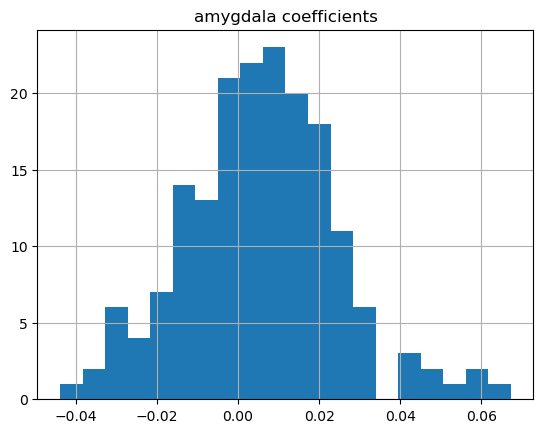

In [1128]:
amyg_idxs = pca_comp_df.index.str.contains("Amygdala")
pca_comp_df.loc[amyg_idxs][[8]].hist(bins=20)
plt.title('amygdala coefficients')
#plt.xlim([-0.06,0.06])

Text(0.5, 1.0, 'DStr coefficients')

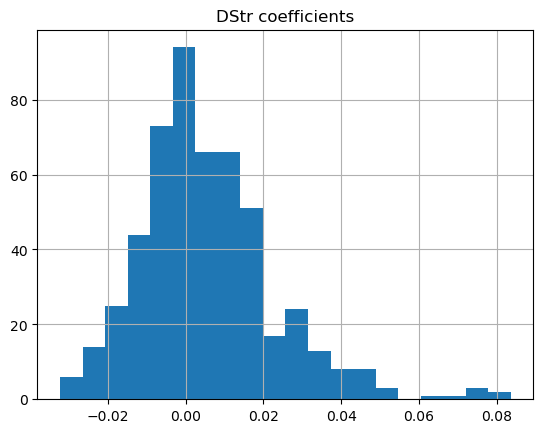

In [1131]:
idxs1 = pca_comp_df.index.str.contains("Caudate")
idxs2 = pca_comp_df.index.str.contains("Putamen")
idxs3 = pca_comp_df.index.str.contains("Pallidum")
dstr_idxs = idxs1 | idxs2 | idxs3
pca_comp_df.loc[dstr_idxs][[9]].hist(bins=20)
plt.title('DStr coefficients')
#plt.xlim([-0.08,0.08])

Text(0.5, 1.0, 'Orb coefficients')

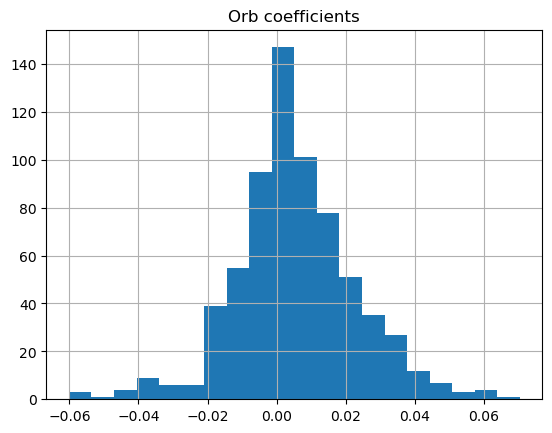

In [1133]:
orb_idxs = pca_comp_df.index.str.contains("Orb_")
pca_comp_df.loc[orb_idxs][[10]].hist(bins=20)
plt.title('Orb coefficients')

In [1097]:
pca_comp_df.loc[idxs][[2]].sum()

2   -0.697108
dtype: float64

In [1126]:
pca_comp_df.loc[orb_idxs][[7]].sort_values(7,ascending=True)[:20]

,7
"Hippocampus_L,Frontal_Mid_Orb_R",-0.054572
"Parietal_Inf_L,Frontal_Sup_Orb_R",-0.053465
"Frontal_Inf_Orb_R,Frontal_Sup_Orb_R",-0.048981
"Frontal_Mid_Orb_R,Frontal_Sup_L",-0.048352
"Frontal_Inf_Tri_L,Frontal_Sup_Orb_L",-0.046689
"Frontal_Mid_Orb_L,Frontal_Mid_L",-0.045891
"Frontal_Inf_Tri_L,Frontal_Mid_Orb_L",-0.042045
"Frontal_Inf_Orb_R,Frontal_Mid_Orb_L",-0.041690
"Hippocampus_R,Frontal_Mid_Orb_R",-0.040697
"Frontal_Inf_Tri_R,Frontal_Sup_Orb_L",-0.040337


In [1134]:
pca_comp_df.loc[orb_idxs][[10]].sort_values(10,ascending=False)[:20]

,10
"Amygdala_L,Frontal_Inf_Orb_L",0.070346
"Frontal_Inf_Orb_L,Precentral_R",0.061373
"Frontal_Mid_R,Frontal_Sup_Orb_R",0.060754
"Parietal_Inf_R,Frontal_Sup_Orb_L",0.058719
"Amygdala_R,Frontal_Sup_Orb_L",0.058172
"Parietal_Sup_R,Frontal_Sup_Orb_R",0.056779
"Precuneus_L,Frontal_Inf_Orb_R",0.052412
"Parietal_Sup_L,Frontal_Sup_Orb_R",0.051330
"Frontal_Inf_Tri_L,Frontal_Sup_Orb_L",0.049416
"Frontal_Mid_Orb_R,Frontal_Mid_Orb_L",0.049283


In [1112]:
pca_comp_df.loc[dstr_idxs | orb_idxs][[3]].sort_values(3,ascending=False)[:20]

,3
"Pallidum_R,Putamen_R",0.128490
"Pallidum_R,Putamen_L",0.122401
"Putamen_R,Insula_L",0.103986
"Putamen_R,Insula_R",0.099199
"Pallidum_R,Pallidum_L",0.097060
"Pallidum_L,Putamen_L",0.084673
"Occipital_Mid_R,Frontal_Mid_Orb_L",0.075102
"Pallidum_R,Amygdala_R",0.074332
"Putamen_R,Rolandic_Oper_L",0.063019
"Putamen_R,Cingulum_Post_L",0.053883


In [1086]:
pca_comp_df

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
"Precentral_R,Precentral_L",-0.022224,-0.042461,-0.055587,0.000369,-0.046453,-0.013510,0.003273,-0.024420,0.035864,-0.048601,-0.038376,0.026396,0.060208,-0.023456,-0.000299,-0.002607,-0.164231
"Frontal_Sup_L,Precentral_L",-0.015661,-0.010249,-0.018055,-0.002840,-0.002798,-0.011976,-0.002588,-0.000526,0.014505,-0.005576,-0.006876,0.006445,0.002624,0.013610,0.001797,-0.007940,0.301815
"Frontal_Sup_L,Precentral_R",0.015704,-0.013100,0.023155,0.026473,0.005200,-0.015409,0.019310,0.031792,-0.024536,-0.025636,-0.017451,-0.015579,0.002429,-0.031795,0.000479,-0.017744,-0.226851
"Frontal_Sup_R,Precentral_L",-0.002741,0.008377,0.006505,0.012552,-0.013309,-0.017255,0.017718,0.010733,-0.020830,-0.027612,0.007035,0.002060,0.002823,-0.007679,0.013914,0.000228,-0.434439
"Frontal_Sup_R,Precentral_R",0.001314,-0.013783,-0.015595,-0.005527,-0.010343,0.005017,0.001110,-0.003210,-0.003844,0.000130,-0.002098,-0.004093,-0.003773,0.005955,-0.008990,0.016460,0.101140
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Temporal_Inf_R,Temporal_Mid_L",0.000274,0.003249,-0.007559,-0.009250,0.000661,0.014983,0.005023,-0.014429,0.002566,-0.002470,-0.005414,-0.001667,-0.028791,0.010626,-0.014385,-0.014050,-0.005547
"Temporal_Inf_R,Temporal_Mid_R",0.014582,0.031805,-0.011594,0.004902,-0.002593,-0.001331,0.019788,0.009024,0.028076,-0.015858,-0.020700,-0.014486,-0.053055,-0.014381,-0.000785,-0.016942,-0.002656
"Temporal_Inf_R,Temporal_Pole_Mid_L",0.002156,-0.007108,-0.000315,-0.002716,-0.002075,-0.004431,-0.008286,-0.001419,0.002614,0.003542,-0.007020,-0.011391,-0.008433,0.012853,0.013241,-0.001637,-0.000453
"Temporal_Inf_R,Temporal_Pole_Mid_R",0.002949,0.003965,0.003181,0.031711,-0.009263,-0.012548,0.011335,0.006062,-0.019833,-0.022441,-0.025160,-0.007992,-0.017999,-0.025554,-0.009058,0.005099,-0.001248


In [1061]:
sorted_indices = (pca_comp_df[1]).sort_values(ascending=False).index

pca_comp_df.loc[sorted_indices[:25]][[1]]

,1
"SupraMarginal_R,Cingulum_Mid_R",0.103411
"Cingulum_Post_L,Frontal_Med_Orb_L",0.089353
"Putamen_L,Rolandic_Oper_R",0.084004
"SupraMarginal_L,Cingulum_Mid_R",0.083619
"Insula_L,Frontal_Mid_Orb_R",0.081185
"Cingulum_Mid_R,Frontal_Med_Orb_L",0.080356
"Pallidum_R,Rolandic_Oper_R",0.075979
"Putamen_R,Rolandic_Oper_L",0.075080
"Parietal_Inf_L,Cingulum_Mid_R",0.074168
"Putamen_R,Rectus_L",0.072095


In [1062]:
sorted_indices = (-pca_comp_df[1]).sort_values(ascending=False).index

pca_comp_df.loc[sorted_indices[:25]][[1]]

,1
"Pallidum_L,Fusiform_L",-0.066991
"Putamen_R,Insula_R",-0.060468
"Amygdala_L,Frontal_Inf_Tri_L",-0.059242
"Paracentral_Lobule_L,Calcarine_R",-0.058621
"Paracentral_Lobule_L,Precentral_L",-0.055404
"Thalamus_R,Thalamus_L",-0.051097
"Temporal_Pole_Mid_L,Frontal_Inf_Orb_L",-0.049947
"Temporal_Inf_R,Supp_Motor_Area_L",-0.047763
"Parietal_Sup_R,Cingulum_Ant_L",-0.047399
"Parietal_Inf_R,Amygdala_R",-0.047370


In [1063]:
sorted_indices = (pca_comp_df[2]).sort_values(ascending=False).index

pca_comp_df.loc[sorted_indices[:25]][[2]]

,2
"Putamen_R,Frontal_Inf_Tri_L",0.128634
"Putamen_L,Frontal_Inf_Tri_L",0.117442
"Insula_R,Frontal_Inf_Orb_R",0.091411
"Insula_L,Frontal_Inf_Orb_R",0.082423
"Amygdala_L,Frontal_Inf_Orb_L",0.080280
"Putamen_L,Frontal_Inf_Oper_R",0.077796
"Putamen_R,Frontal_Mid_Orb_R",0.077129
"Putamen_L,Frontal_Mid_Orb_L",0.070514
"Putamen_L,Parietal_Inf_L",0.068612
"Temporal_Pole_Mid_R,Insula_R",0.068585


In [1064]:
sorted_indices = (-pca_comp_df[2]).sort_values(ascending=False).index

pca_comp_df.loc[sorted_indices[:25]][[2]]

,2
"Putamen_R,Rolandic_Oper_L",-0.066992
"Calcarine_R,Frontal_Sup_Orb_R",-0.066795
"Putamen_R,Insula_L",-0.058028
"Putamen_R,Cingulum_Post_L",-0.056993
"Putamen_R,Insula_R",-0.056533
"Postcentral_R,Postcentral_L",-0.054115
"Frontal_Med_Orb_R,Frontal_Inf_Oper_R",-0.050992
"Thalamus_R,Frontal_Sup_L",-0.050047
"Putamen_L,Insula_L",-0.049855
"Frontal_Med_Orb_L,Frontal_Inf_Oper_R",-0.049375


In [1065]:
sorted_indices = (pca_comp_df[3]).sort_values(ascending=False).index

pca_comp_df.loc[sorted_indices[:25]][[3]]

,3
"Pallidum_R,Putamen_R",0.128490
"Pallidum_R,Putamen_L",0.122401
"Putamen_R,Insula_L",0.103986
"Amygdala_R,Amygdala_L",0.101426
"Putamen_R,Insula_R",0.099199
"Pallidum_R,Pallidum_L",0.097060
"Olfactory_R,Olfactory_L",0.094887
"Pallidum_L,Putamen_L",0.084673
"Hippocampus_R,Frontal_Sup_Medial_L",0.081842
"Occipital_Mid_R,Frontal_Mid_Orb_L",0.075102


In [1067]:
sorted_indices = (-pca_comp_df[3]).sort_values(ascending=False).index

pca_comp_df.loc[sorted_indices[:25]][[3]]

,3
"Postcentral_R,Postcentral_L",-0.078493
"Postcentral_L,Precentral_R",-0.070368
"Temporal_Pole_Mid_L,Frontal_Inf_Orb_L",-0.065752
"Amygdala_L,Frontal_Inf_Tri_L",-0.062351
"Amygdala_L,Frontal_Inf_Oper_L",-0.058876
"Precentral_R,Precentral_L",-0.055587
"Amygdala_R,Frontal_Sup_Medial_R",-0.055481
"Temporal_Inf_L,Frontal_Sup_R",-0.051079
"Putamen_R,Frontal_Inf_Tri_R",-0.047683
"Pallidum_R,Supp_Motor_Area_R",-0.046570


In [979]:
sorted_indices = (pca_comp_df[4]).sort_values(ascending=False).index

pca_comp_df.loc[sorted_indices[:25]][[4]]

,4
"SupraMarginal_R,Frontal_Mid_L",0.110542
"Temporal_Pole_Mid_L,Hippocampus_L",0.090791
"Parietal_Inf_R,Frontal_Mid_L",0.088781
"Amygdala_L,Frontal_Mid_L",0.086092
"Temporal_Pole_Mid_L,ParaHippocampal_L",0.083323
"Thalamus_L,ParaHippocampal_R",0.077068
"Temporal_Pole_Mid_L,Hippocampus_R",0.068041
"Parietal_Inf_R,Insula_R",0.066865
"Temporal_Pole_Mid_L,Amygdala_L",0.066272
"Temporal_Pole_Mid_L,ParaHippocampal_R",0.064362


In [980]:
sorted_indices = (-pca_comp_df[4]).sort_values(ascending=False).index

pca_comp_df.loc[sorted_indices[:25]][[4]]

,4
"Calcarine_R,Frontal_Sup_Orb_R",-0.078295
"Cingulum_Post_R,Supp_Motor_Area_R",-0.067314
"Parietal_Inf_L,Frontal_Sup_Orb_L",-0.059275
"Paracentral_Lobule_L,Precentral_L",-0.058854
"Frontal_Mid_R,Frontal_Sup_Orb_R",-0.058102
"Amygdala_R,Cingulum_Post_L",-0.057923
"Amygdala_R,Frontal_Sup_Medial_R",-0.056267
"Thalamus_R,Cingulum_Ant_L",-0.055965
"Insula_R,Frontal_Inf_Orb_R",-0.054927
"Occipital_Sup_L,Olfactory_L",-0.054591


In [943]:
# cluster 4
sorted_indices = (pca_comp_df[1]).sort_values(ascending=False).index

pca_comp_df.loc[sorted_indices[:25]]

,1,2
"Cingulum_Post_L,Frontal_Med_Orb_L",0.096718,-0.035237
"SupraMarginal_R,Cingulum_Mid_R",0.093542,-0.025511
"Insula_L,Frontal_Mid_Orb_R",0.081910,-0.003868
"Cingulum_Mid_R,Frontal_Med_Orb_L",0.077275,0.006451
"Calcarine_R,Cingulum_Mid_R",0.075689,-0.013805
"Parietal_Inf_L,Cingulum_Mid_R",0.072446,-0.012951
"Putamen_L,Rolandic_Oper_R",0.070072,-0.009865
"Putamen_R,Rectus_L",0.069876,0.005351
"SupraMarginal_L,Cingulum_Mid_R",0.065343,-0.021596
"Cuneus_L,Cingulum_Mid_R",0.064906,-0.023287


In [944]:
# cluster 0
sorted_indices = (-pca_comp_df[1] - pca_comp_df[2]).sort_values(ascending=False).index

pca_comp_df.loc[sorted_indices[:25]]

,1,2
"Pallidum_L,Fusiform_L",-0.073970,-0.070386
"Temporal_Pole_Mid_L,Frontal_Inf_Orb_L",-0.066068,-0.074399
"Occipital_Sup_R,Hippocampus_L",-0.052360,-0.074652
"Amygdala_R,Frontal_Sup_Medial_R",-0.044501,-0.074753
"Temporal_Mid_R,Temporal_Mid_L",-0.060126,-0.053800
"Occipital_Inf_R,Olfactory_L",-0.046380,-0.064228
"Occipital_Sup_L,Olfactory_R",-0.047505,-0.055296
"Paracentral_Lobule_L,Calcarine_R",-0.060356,-0.032048
"Occipital_Sup_L,Olfactory_L",-0.046411,-0.044213
"Amygdala_R,Cingulum_Post_L",-0.058427,-0.029567


In [798]:
# cluster 2
sorted_indices = (-pca_comp_df[1] + pca_comp_df[2]).sort_values(ascending=False).index

pca_comp_df.loc[sorted_indices[:25]]

,1,2
"Putamen_R,Insula_L",-0.045046,0.110697
"Putamen_R,Insula_R",-0.070301,0.076036
"Pallidum_R,Putamen_L",-0.036155,0.103605
"Pallidum_R,Putamen_R",-0.028557,0.105002
"Putamen_R,Rolandic_Oper_L",-0.025183,0.091698
"Amygdala_R,Amygdala_L",-0.019374,0.091320
"Occipital_Mid_R,Frontal_Mid_Orb_L",-0.030122,0.077123
"Frontal_Inf_Oper_R,Frontal_Sup_Orb_R",-0.049658,0.057053
"Hippocampus_R,Frontal_Sup_Medial_L",-0.031181,0.070458
"Pallidum_R,Pallidum_L",-0.028063,0.072168


In [799]:
# cluster 2
sorted_indices = (-pca_comp_df[1]).sort_values(ascending=False).index

pca_comp_df.loc[sorted_indices[:25]]

,1,2
"Calcarine_R,Frontal_Sup_Orb_R",-0.078649,-0.003948
"Putamen_R,Insula_R",-0.070301,0.076036
"Paracentral_Lobule_L,Calcarine_R",-0.059098,-0.039957
"Temporal_Pole_Mid_L,Frontal_Inf_Orb_L",-0.058422,-0.081804
"Calcarine_L,Frontal_Sup_Orb_R",-0.056421,-0.003840
"Putamen_L,Insula_L",-0.056253,0.034162
"Temporal_Mid_R,Temporal_Mid_L",-0.053896,-0.062229
"Temporal_Mid_L,Rolandic_Oper_R",-0.053540,-0.019012
"Amygdala_R,Cingulum_Post_L",-0.051318,-0.040550
"Putamen_R,Cingulum_Post_L",-0.050983,0.045180


array([[<Axes: title={'center': '1'}>, <Axes: title={'center': '2'}>],
       [<Axes: title={'center': '3'}>, <Axes: >]], dtype=object)

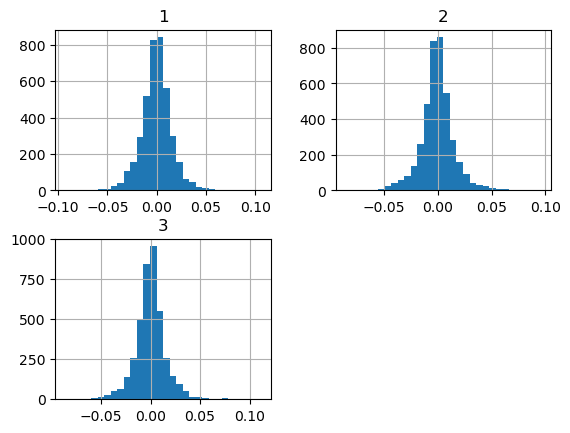

In [728]:
pca_comp_df.hist(bins=30)

# look at decision landscape for clusters

In [683]:
data = np.zeros((len(scores_of_interest),corr2_tri_vs[1].shape[0]))
for i in range(data.shape[0]):
    data[i,:] = corr2_tri_vs[scores_of_interest[i]]
scaled_data = preprocessing.normalize(data, norm='l2',axis=1)

In [684]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier

embedding = embedding[:,:3]
#clf = SVC(kernel='linear')
clf = DecisionTreeClassifier(max_depth=4)
clf.fit(embedding,score_clusters)
pred = clf.predict(embedding)

In [685]:
pred

array([0, 2, 3, 3, 3, 0, 2, 2, 4, 4, 4, 2], dtype=int64)

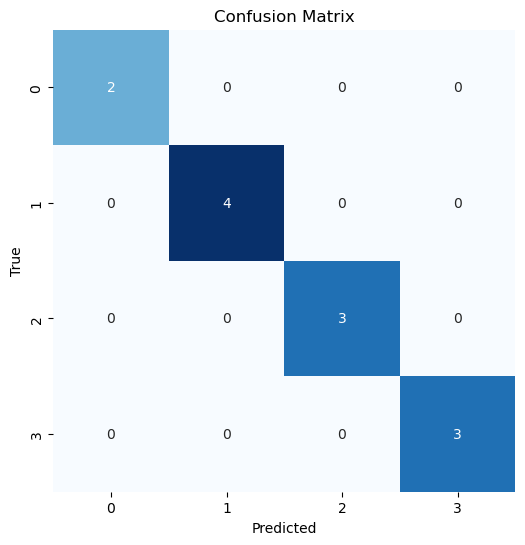

In [686]:
from sklearn.metrics import accuracy_score, confusion_matrix
accuracy = accuracy_score(score_clusters, pred)
conf_m = confusion_matrix(score_clusters, pred)

#Display the confusion matrix as a heatmap
plt.figure(figsize=(6, 6))
sns.heatmap(conf_m, annot=True, fmt="d", cmap="Blues", cbar=False, square=True)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

In [687]:
x_min,x_max = embedding[:,0].min(),embedding[:,0].max()
y_min,y_max = embedding[:,1].min(),embedding[:,1].max()
z_min,z_max = embedding[:,2].min(),embedding[:,2].max()
xx,yy,zz = np.meshgrid(np.arange(x_min, x_max, 0.02),
            np.arange(y_min, y_max, 0.02),
            np.arange(z_min, z_max, 0.02))

clustergrid = clf.predict(np.c_[xx.ravel(), yy.ravel(), zz.ravel()])
clustergrid = clustergrid.reshape(xx.shape)

In [690]:
color_dict

{3: array([0.267004, 0.004874, 0.329415, 1.      ]),
 0: array([0.190631, 0.407061, 0.556089, 1.      ]),
 4: array([0.20803 , 0.718701, 0.472873, 1.      ]),
 2: array([0.993248, 0.906157, 0.143936, 1.      ])}

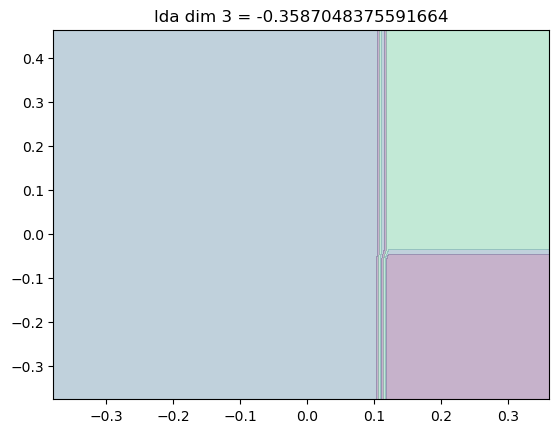

In [691]:
zslice_value = np.percentile(zz, 10,method='nearest')
zslice = (zz==zslice_value).nonzero()[2][0]

zslice_x = xx[:,:,zslice]
zslice_y = yy[:,:,zslice]
zslice_clusters = clustergrid[:,:,zslice]

zslice_cluster_values = np.unique(zslice_clusters)
zslice_colors = [color_dict[c] for c in zslice_cluster_values]

plt.title(f"lda dim 3 = {zslice_value}")
plt.contourf(zslice_x, zslice_y, zslice_clusters, alpha=0.3, colors = zslice_colors)

In [ ]:
zslice_value = np.percentile(zz, 10,method='nearest')
zslice = (zz==zslice_value).nonzero()[2][0]

zslice_x = xx[:,:,zslice]
zslice_y = yy[:,:,zslice]
zslice_clusters = clustergrid[:,:,zslice]

zslice_cluster_values = np.unique(zslice_clusters)
zslice_colors = [color_dict[c] for c in zslice_cluster_values]

plt.title(f"lda dim 3 = {zslice_value}")
plt.contourf(zslice_x, zslice_y, zslice_clusters, alpha=0.3, colors = zslice_colors)

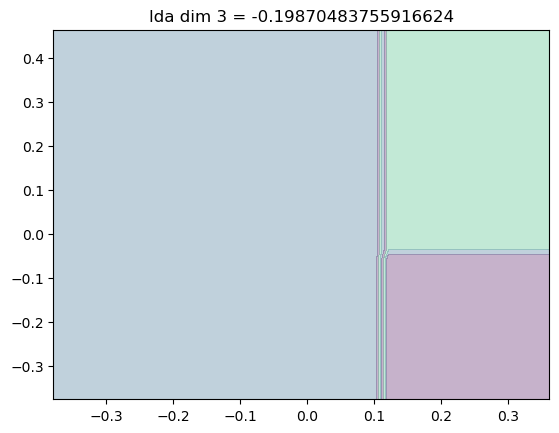

In [692]:
zslice_value = np.percentile(zz, 30,method='nearest')
zslice = (zz==zslice_value).nonzero()[2][0]

zslice_x = xx[:,:,zslice]
zslice_y = yy[:,:,zslice]
zslice_clusters = clustergrid[:,:,zslice]

zslice_cluster_values = np.unique(zslice_clusters)
zslice_colors = [color_dict[c] for c in zslice_cluster_values]

plt.title(f"lda dim 3 = {zslice_value}")
plt.contourf(zslice_x, zslice_y, zslice_clusters, alpha=0.3, colors = zslice_colors)

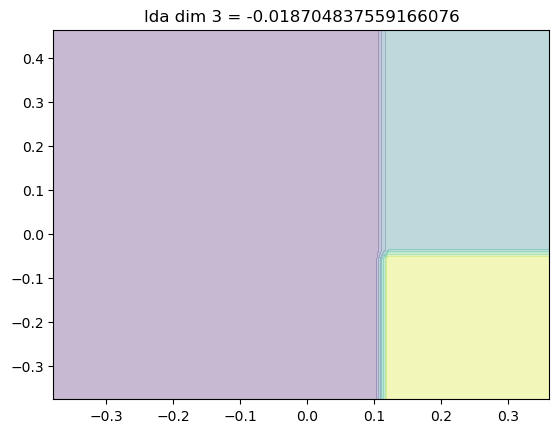

In [696]:
zslice_value = np.percentile(zz, 50,method='nearest')
zslice = (zz==zslice_value).nonzero()[2][0]

zslice_x = xx[:,:,zslice]
zslice_y = yy[:,:,zslice]
zslice_clusters = clustergrid[:,:,zslice]

zslice_cluster_values = np.unique(zslice_clusters)
zslice_colors = [color_dict[c] for c in zslice_cluster_values]

plt.title(f"lda dim 3 = {zslice_value}")
#plt.contourf(zslice_x, zslice_y, zslice_clusters, alpha=0.3, colors = zslice_colors)
plt.contourf(zslice_x, zslice_y, zslice_clusters, alpha=0.3, cmap = 'viridis')

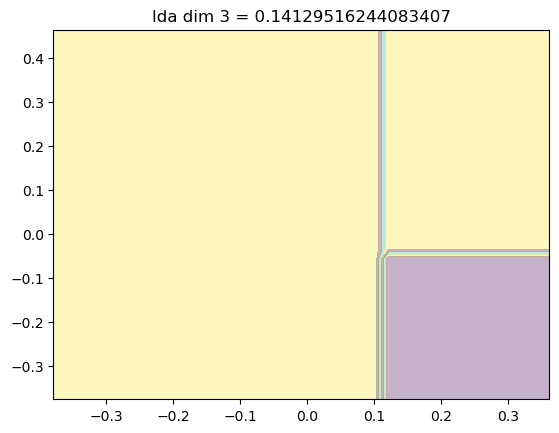

In [694]:
zslice_value = np.percentile(zz, 70,method='nearest')
zslice = (zz==zslice_value).nonzero()[2][0]

zslice_x = xx[:,:,zslice]
zslice_y = yy[:,:,zslice]
zslice_clusters = clustergrid[:,:,zslice]

zslice_cluster_values = np.unique(zslice_clusters)
zslice_colors = [color_dict[c] for c in zslice_cluster_values]

plt.title(f"lda dim 3 = {zslice_value}")
plt.contourf(zslice_x, zslice_y, zslice_clusters, alpha=0.3, colors = zslice_colors)

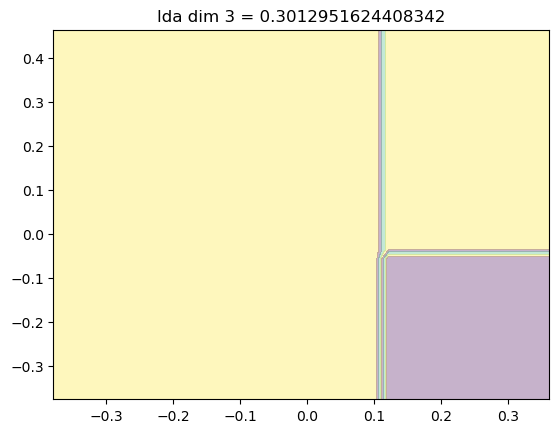

In [695]:
zslice_value = np.percentile(zz, 90,method='nearest')
zslice = (zz==zslice_value).nonzero()[2][0]

zslice_x = xx[:,:,zslice]
zslice_y = yy[:,:,zslice]
zslice_clusters = clustergrid[:,:,zslice]

zslice_cluster_values = np.unique(zslice_clusters)
zslice_colors = [color_dict[c] for c in zslice_cluster_values]

plt.title(f"lda dim 3 = {zslice_value}")
plt.contourf(zslice_x, zslice_y, zslice_clusters, alpha=0.3, colors = zslice_colors)

# project scores to planes highlighting angles

In [489]:
clusters_of_interest = [3,0,4,2]
scores = np.array([r+1 for r in ridx])
scores_of_interest = scores[[True if c in clusters_of_interest else False for c in clusters]]
score_clusters = [c for c in clusters if c in clusters_of_interest]

In [490]:
scores_of_interest

array([ 2,  6,  4,  5,  1,  7, 11, 10, 13,  8,  3, 14])

In [491]:
score_clusters

[0, 2, 3, 3, 3, 0, 2, 2, 4, 4, 4, 2]

In [492]:
clusters

[0, 1, 2, 3, 3, 3, 0, 2, 2, 4, 4, 5, 4, 6, 2, 7, 8]

In [494]:
clusters_of_interest

[3, 0, 4, 2]

In [496]:
clusters

[0, 1, 2, 3, 3, 3, 0, 2, 2, 4, 4, 5, 4, 6, 2, 7, 8]

In [466]:
def project_vector_to_plane(x,v1,v2):
    u1 = v1 / np.linalg.norm(v1)
    v2_orthogonal = v2 - np.dot(v2, u1) * u1
    u2 = v2_orthogonal / np.linalg.norm(v2_orthogonal)
    projection_x = np.dot(x,u1) * u1 + np.dot(x, u2) * u2
    return x

In [467]:
plane_scores = [1,7]

v1 = corr2_tri_vs[1]
v2 = corr2_tri_vs[7]
x = corr2_tri_vs[3]

In [473]:
u1 = v1 / np.linalg.norm(v1)
v2_orthogonal = v2 - np.dot(v2, u1) * u1
u2 = v2_orthogonal / np.linalg.norm(v2_orthogonal)

In [487]:
cmap = plt.colormaps['viridis']
color_vector = cmap(np.linspace(0,1, 17))

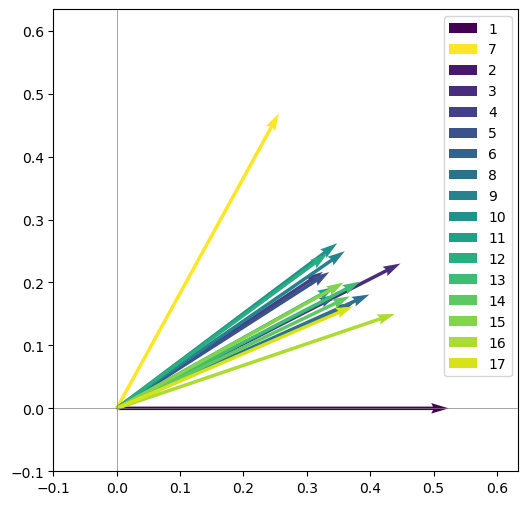

In [488]:
plt.figure(figsize=(6, 6))

plt.quiver(0, 0, np.dot(u1,v1), np.dot(u2,v1), angles='xy', scale_units='xy', scale=1, color=color_vector[0], label='1')
plt.quiver(0, 0,np.dot(u1,v2), np.dot(u2,v2), angles='xy', scale_units='xy', scale=1, color=color_vector[-1], label='7')

color_index = 1
for s in range(1,18):
    if s in [1,7]:
        continue
    x = x = corr2_tri_vs[s]
    norm_x = x / np.linalg.norm(x)
    plt.quiver(0, 0,np.dot(u1,norm_x), np.dot(u2,norm_x), angles='xy', scale_units='xy', scale=1, label=s,color=color_vector[color_index])
    color_index = color_index+1

plt.xlim(-0.1, max(norm_u, norm_v) + 0.1)
plt.ylim(-0.1, max(norm_u, norm_v) + 0.1)
plt.axhline(0, color='gray', lw=0.5)
plt.axvline(0, color='gray', lw=0.5)
#plt.grid(True)
#plt.title(f'Angle between N-D vectors: {angle_deg:.2f}°')
plt.legend()
plt.show()

In [460]:
v1 = corr2_tri_vs[1]
v2 = corr2_tri_vs[7]
x = corr2_tri_vs[2]
u1 = v1 / np.linalg.norm(v1)
v2_orthogonal = v2 - np.dot(v2, u1) * u1
u2 = v2_orthogonal / np.linalg.norm(v2_orthogonal)
projection_x = np.dot(x,u1) * u1 + np.dot(x, u2) * u2

In [ ]:
plt.figure(figsize=(6, 6))
plt.quiver(0, 0, x_u, y_u, angles='xy', scale_units='xy', scale=1, color='blue', label='v1 (projected)')
plt.quiver(0, 0, x_v, y_v, angles='xy', scale_units='xy', scale=1, color='red', label='v2 (projected)')
plt.xlim(-1, max(norm_u, norm_v) + 1)
plt.ylim(-1, max(norm_u, norm_v) + 1)
plt.axhline(0, color='gray', lw=0.5)
plt.axvline(0, color='gray', lw=0.5)
plt.grid(True)
plt.title(f'Angle between N-D vectors: {angle_deg:.2f}°')
plt.legend()
plt.show()

In [464]:
 np.dot(x,u1)

0.220869183434668

In [465]:
 np.dot(x, u2)

0.09888670001805287

# search R2 matrices for circuits of interest

In [1212]:
region_scores = np.zeros((17,corr2_ms[1].shape[0]))
region_scores_df = pd.DataFrame(region_scores,columns=cols,index=range(1,18))

In [1222]:
corr_ms[q][i,:]

array([ 0.13122679,  0.00743786, -0.11558205, -0.10628476,  0.00371659,
       -0.03552826,  0.00181763, -0.0678742 , -0.07598485, -0.05566392,
        0.17278861,  0.10177748,  0.08454087,  0.04696423,  0.04494693,
       -0.02477713,  0.06525623,  0.12172921, -0.05553387, -0.11642057,
       -0.14385096, -0.11855878, -0.1141721 , -0.12604103, -0.03278211,
       -0.04691695, -0.05427641, -0.0865243 ,  0.04914226,  0.0596264 ,
       -0.10673235, -0.12606647,  0.0074553 , -0.02450084, -0.11044362,
       -0.05480831, -0.01168663,  0.07102981, -0.17031038, -0.06232837,
        0.        , -0.02096281,  0.01124068,  0.06988466,  0.03508294,
        0.07491098,  0.00179875,  0.00562739,  0.11494502,  0.13851931,
        0.14751959,  0.20174462,  0.162717  ,  0.1562378 , -0.01837196,
       -0.0391237 ,  0.08371363,  0.07017181,  0.06816314,  0.13815131,
        0.0641983 ,  0.0702542 ,  0.12249199,  0.1246053 , -0.03891563,
       -0.06213967,  0.02575658,  0.03307002, -0.04210462, -0.06

In [1224]:
corr_ms[q][i+1,:]

array([ 0.1096562 ,  0.09106733, -0.1450552 , -0.19861087, -0.10776579,
       -0.08451751, -0.02638347, -0.04023739, -0.07167675, -0.0278094 ,
        0.09900139,  0.09894943,  0.02209532,  0.02078814, -0.05022078,
       -0.01508561,  0.06913185,  0.15724837,  0.03302082, -0.07598852,
       -0.18116582, -0.11338413, -0.22452881, -0.28736046, -0.18023731,
       -0.14781549, -0.198643  , -0.20211765,  0.08783127,  0.13189034,
       -0.14764005, -0.14847746,  0.04106266, -0.01161046, -0.2326892 ,
       -0.13272455,  0.04987352,  0.03875562, -0.04665   , -0.07844101,
       -0.02096281,  0.        ,  0.05906867,  0.07654641,  0.11761161,
        0.12754357,  0.09783282,  0.08819883,  0.18343358,  0.17944039,
        0.06518951,  0.13531876,  0.15584117,  0.09386561,  0.14800884,
        0.08109376,  0.10514436,  0.11010614,  0.03380396,  0.06622884,
        0.02518027,  0.00897331,  0.09996572,  0.15760028, -0.15541536,
       -0.10909986, -0.05903933, -0.07437583, -0.03322295, -0.07

In [1225]:
corr_ms[q][i,:].sum()

0.5319643090144763

In [1226]:
corr_ms[q][i+1,:].sum()

-0.7481522996703867

In [1227]:
corr_ms[q][i,:].sum() + corr_ms[q][i+1,:].sum()

-0.21618799065591032

In [1228]:
corr2_ms[q][i,:]

array([1.72204711e-02, 5.53217673e-05, 1.33592105e-02, 1.12964508e-02,
       1.38130612e-05, 1.26225694e-03, 3.30378080e-06, 4.60690670e-03,
       5.77369695e-03, 3.09847248e-03, 2.98559026e-02, 1.03586552e-02,
       7.14715886e-03, 2.20563920e-03, 2.02022672e-03, 6.13906415e-04,
       4.25837542e-03, 1.48179994e-02, 3.08401078e-03, 1.35537497e-02,
       2.06930981e-02, 1.40561843e-02, 1.30352686e-02, 1.58863419e-02,
       1.07466652e-03, 2.20119997e-03, 2.94592893e-03, 7.48645390e-03,
       2.41496185e-03, 3.55530721e-03, 1.13917945e-02, 1.58927544e-02,
       5.55815101e-05, 6.00291107e-04, 1.21977937e-02, 3.00395133e-03,
       1.36577283e-04, 5.04523330e-03, 2.90056267e-02, 3.88482525e-03,
       0.00000000e+00, 4.39439367e-04, 1.26352959e-04, 4.88386537e-03,
       1.23081247e-03, 5.61165483e-03, 3.23549068e-06, 3.16675608e-05,
       1.32123577e-02, 1.91876003e-02, 2.17620294e-02, 4.07008934e-02,
       2.64768228e-02, 2.44102488e-02, 3.37528794e-04, 1.53066404e-03,
      

In [1229]:
corr2_ms[q][i+1,:]

array([1.20244818e-02, 8.29325818e-03, 2.10410117e-02, 3.94462795e-02,
       1.16134647e-02, 7.14320943e-03, 6.96087736e-04, 1.61904754e-03,
       5.13755682e-03, 7.73362848e-04, 9.80127615e-03, 9.79099022e-03,
       4.88203105e-04, 4.32146731e-04, 2.52212698e-03, 2.27575607e-04,
       4.77921257e-03, 2.47270509e-02, 1.09037430e-03, 5.77425495e-03,
       3.28210538e-02, 1.28559611e-02, 5.04131857e-02, 8.25760367e-02,
       3.24854896e-02, 2.18494202e-02, 3.94590414e-02, 4.08515455e-02,
       7.71433196e-03, 1.73950631e-02, 2.17975840e-02, 2.20455574e-02,
       1.68614226e-03, 1.34802828e-04, 5.41442628e-02, 1.76158062e-02,
       2.48736782e-03, 1.50199839e-03, 2.17622244e-03, 6.15299152e-03,
       4.39439367e-04, 0.00000000e+00, 3.48910775e-03, 5.85935300e-03,
       1.38324899e-02, 1.62673611e-02, 9.57126025e-03, 7.77903296e-03,
       3.36478783e-02, 3.21988535e-02, 4.24967178e-03, 1.83111662e-02,
       2.42864699e-02, 8.81075250e-03, 2.19066166e-02, 6.57619763e-03,
      

In [1230]:
corr2_ms[q][i,:].sum()

0.6875065013672442

In [1231]:
corr2_ms[q][i+1,:].sum()

1.0454644067770567

In [1232]:
corr2_ms[q][i,:].sum() + corr2_ms[q][i+1,:].sum()

1.732970908144301

In [1233]:
for q in range(1,18):
    for i,r in enumerate(cols):
        region_scores_df.loc[q,r] = corr_ms[q][i,:].sum()

In [1234]:
region_scores_df

,Precentral_L,Precentral_R,Frontal_Sup_L,Frontal_Sup_R,Frontal_Sup_Orb_L,Frontal_Sup_Orb_R,Frontal_Mid_L,Frontal_Mid_R,Frontal_Mid_Orb_L,Frontal_Mid_Orb_R,...,Temporal_Sup_L,Temporal_Sup_R,Temporal_Pole_Sup_L,Temporal_Pole_Sup_R,Temporal_Mid_L,Temporal_Mid_R,Temporal_Pole_Mid_L,Temporal_Pole_Mid_R,Temporal_Inf_L,Temporal_Inf_R
1,0.612514,-0.465192,-0.759996,-0.801262,0.816717,0.674725,0.395398,-0.293587,-0.320950,-0.362048,...,0.045741,-0.048483,0.673432,0.814498,-0.574474,-0.273347,0.406467,-0.401784,-0.409092,-0.106233
2,-0.194850,-1.294820,-0.213822,0.378414,1.255226,1.312885,0.507641,1.581470,1.030509,1.547702,...,0.880637,0.522408,2.029015,1.002934,0.882921,1.598586,2.032807,1.250807,1.529389,2.489859
3,1.197089,0.189130,-0.994077,-1.021282,-0.520322,-1.188927,-0.865704,-0.821639,-0.617253,-1.092022,...,-0.758134,-0.084045,-0.731815,-0.690485,-1.099717,-1.012231,-0.305057,-0.526012,-1.165678,-0.767320
4,0.655172,0.871398,0.029769,-0.404275,0.636454,0.842190,0.457910,0.303565,2.755831,2.349616,...,2.000105,1.890136,0.788078,0.311112,-0.390834,-0.173437,-0.710684,0.759794,-0.232138,0.322050
5,0.692695,-0.063129,0.517840,-1.094975,-0.280343,-0.920361,1.673270,0.730014,1.372617,0.795579,...,1.001993,0.282948,-0.077467,-0.267604,0.790139,-0.900031,-0.440990,-0.864055,1.394878,0.767617
6,1.486443,1.655559,-0.363721,-0.129558,1.198363,1.111350,-0.903356,0.068031,1.028258,1.557115,...,1.771812,1.889270,1.053845,0.724722,1.119206,0.103190,0.066950,0.350723,0.974829,1.314845
7,0.356034,-0.576501,-0.625772,-1.840620,0.073705,-1.205702,0.738543,-1.316460,-0.941168,-1.193302,...,0.599627,0.869108,1.372642,0.119882,0.894753,0.451276,0.020431,-0.319937,-1.601192,-1.258635
8,0.555256,-1.129891,1.492276,-0.408959,0.098081,-0.998888,2.136152,-0.274860,-0.823035,-1.137910,...,-1.994409,-3.211791,-0.341739,-2.359436,-1.374186,-2.975389,-0.341966,-1.452894,-0.024440,-1.708273
9,-0.083226,0.124262,-0.104948,-2.093593,-0.066102,-0.325973,0.126873,-0.819922,-0.119190,0.099095,...,-0.283812,-1.028427,0.292244,0.691652,-1.854629,-1.459371,0.607865,0.249886,-0.442942,-0.831877
10,0.053689,0.231564,-0.338550,-1.861505,-0.348623,0.253233,0.194759,-0.664578,0.672468,1.643868,...,0.012388,0.231723,-0.207239,-0.248783,0.689465,0.068218,-0.486830,-0.706186,0.061753,0.111560


In [1235]:
sorted_indices = (region_scores_df['Amygdala_L'] + region_scores_df['Amygdala_R']).sort_values(ascending=False).index

region_scores_df.loc[sorted_indices][['Amygdala_L','Amygdala_R']]

,Amygdala_L,Amygdala_R
2,1.907074,1.126878
17,1.124347,0.655939
9,0.539844,1.191349
13,1.362447,0.150972
8,0.263074,0.771515
5,0.280094,0.565845
4,0.590549,0.147465
6,0.486416,0.111127
14,0.287506,-0.042988
10,-0.016641,0.153861


In [1236]:
sorted_indices = (
    region_scores_df['Caudate_L'] + region_scores_df['Caudate_R'] +
    region_scores_df['Putamen_L'] + region_scores_df['Putamen_R'] +
    region_scores_df['Pallidum_L'] + region_scores_df['Pallidum_R']
                 ).sort_values(ascending=False).index

region_scores_df.loc[sorted_indices][['Caudate_L','Caudate_R','Putamen_L','Putamen_R','Pallidum_L','Pallidum_R']]

,Caudate_L,Caudate_R,Putamen_L,Putamen_R,Pallidum_L,Pallidum_R
4,0.990470,0.738192,2.016878,2.066810,2.035004,1.113817
9,1.422122,1.507299,1.362377,2.029072,0.234161,1.085343
5,0.666550,-0.348580,2.085354,1.049844,1.880023,0.995108
13,1.373121,0.592089,1.576969,0.789577,0.724505,0.730764
15,0.166717,-0.107037,0.442140,0.231034,0.592029,0.551355
16,0.470611,-0.159406,0.456069,-0.014351,0.665524,0.142110
14,-0.134372,-0.939025,0.839740,0.611162,0.116750,1.036389
8,1.324552,1.937042,-0.068876,-1.043371,-0.171437,-0.862133
1,-0.209839,-0.053766,0.551025,0.445926,0.245573,0.052518
10,-0.256275,-0.347411,0.444008,-0.183972,0.090984,0.291967


In [1237]:
sorted_indices = (
    region_scores_df['Frontal_Sup_Orb_L'] + region_scores_df['Frontal_Sup_Orb_R'] +
    region_scores_df['Frontal_Mid_Orb_L'] + region_scores_df['Frontal_Mid_Orb_R'] +
    region_scores_df['Frontal_Inf_Orb_L'] + region_scores_df['Frontal_Inf_Orb_R'] +
    region_scores_df['Frontal_Med_Orb_L'] + region_scores_df['Frontal_Med_Orb_R'] 
                 ).sort_values(ascending=False).index

region_scores_df.loc[sorted_indices][['Frontal_Sup_Orb_L','Frontal_Sup_Orb_R','Frontal_Mid_Orb_L','Frontal_Mid_Orb_R',
                                      'Frontal_Inf_Orb_L','Frontal_Inf_Orb_R','Frontal_Med_Orb_L','Frontal_Med_Orb_R']]

,Frontal_Sup_Orb_L,Frontal_Sup_Orb_R,Frontal_Mid_Orb_L,Frontal_Mid_Orb_R,Frontal_Inf_Orb_L,Frontal_Inf_Orb_R,Frontal_Med_Orb_L,Frontal_Med_Orb_R
4,0.636454,0.842190,2.755831,2.349616,1.198112,1.159263,-0.229810,0.094324
2,1.255226,1.312885,1.030509,1.547702,0.552798,0.965210,0.879949,0.850636
6,1.198363,1.111350,1.028258,1.557115,1.096217,0.816705,-0.709582,0.034823
12,0.389145,-0.078425,1.898302,1.814547,0.906816,0.802074,0.000774,-0.453057
14,0.211337,-0.117909,-0.226645,0.307003,0.864938,1.041755,0.331541,0.117471
17,-0.292648,0.177069,0.960282,0.285948,0.182042,-0.573752,0.345761,0.798953
16,0.520270,0.116692,0.466412,0.640935,0.022496,0.392373,0.088139,-0.364577
1,0.816717,0.674725,-0.320950,-0.362048,-0.294710,0.259557,0.179091,0.382192
5,-0.280343,-0.920361,1.372617,0.795579,1.289361,0.590392,-2.039540,-2.461111
9,-0.066102,-0.325973,-0.119190,0.099095,0.013020,-0.299690,-0.503501,-1.039836


In [1238]:
region_scores_df[['Caudate_L','Caudate_R','Putamen_L','Putamen_R','Pallidum_L','Pallidum_R','Frontal_Sup_Orb_L','Frontal_Sup_Orb_R','Frontal_Mid_Orb_L','Frontal_Mid_Orb_R',
                  'Frontal_Inf_Orb_L','Frontal_Inf_Orb_R','Frontal_Med_Orb_L','Frontal_Med_Orb_R',
                  'Amygdala_L','Amygdala_R']]

,Caudate_L,Caudate_R,Putamen_L,Putamen_R,Pallidum_L,Pallidum_R,Frontal_Sup_Orb_L,Frontal_Sup_Orb_R,Frontal_Mid_Orb_L,Frontal_Mid_Orb_R,Frontal_Inf_Orb_L,Frontal_Inf_Orb_R,Frontal_Med_Orb_L,Frontal_Med_Orb_R,Amygdala_L,Amygdala_R
1,-0.209839,-0.053766,0.551025,0.445926,0.245573,0.052518,0.816717,0.674725,-0.320950,-0.362048,-0.294710,0.259557,0.179091,0.382192,-0.388067,-0.085253
2,-0.196246,0.412614,0.149855,0.309803,-1.363320,-1.014497,1.255226,1.312885,1.030509,1.547702,0.552798,0.965210,0.879949,0.850636,1.907074,1.126878
3,0.576394,0.129909,0.011872,0.005568,-0.897850,-1.143332,-0.520322,-1.188927,-0.617253,-1.092022,-1.351745,-1.287688,-1.542735,-1.614926,-1.381438,-0.709091
4,0.990470,0.738192,2.016878,2.066810,2.035004,1.113817,0.636454,0.842190,2.755831,2.349616,1.198112,1.159263,-0.229810,0.094324,0.590549,0.147465
5,0.666550,-0.348580,2.085354,1.049844,1.880023,0.995108,-0.280343,-0.920361,1.372617,0.795579,1.289361,0.590392,-2.039540,-2.461111,0.280094,0.565845
6,0.158539,-0.681569,0.422234,0.194700,0.142546,-0.749186,1.198363,1.111350,1.028258,1.557115,1.096217,0.816705,-0.709582,0.034823,0.486416,0.111127
7,0.273322,-0.909501,0.168171,-0.254600,0.737821,-0.229891,0.073705,-1.205702,-0.941168,-1.193302,0.279750,-0.608636,-0.360283,-0.718096,0.531964,-0.748152
8,1.324552,1.937042,-0.068876,-1.043371,-0.171437,-0.862133,0.098081,-0.998888,-0.823035,-1.137910,-1.115667,-1.923103,-0.966993,-2.211154,0.263074,0.771515
9,1.422122,1.507299,1.362377,2.029072,0.234161,1.085343,-0.066102,-0.325973,-0.119190,0.099095,0.013020,-0.299690,-0.503501,-1.039836,0.539844,1.191349
10,-0.256275,-0.347411,0.444008,-0.183972,0.090984,0.291967,-0.348623,0.253233,0.672468,1.643868,0.507365,-0.207832,-2.444328,-2.634012,-0.016641,0.153861


In [1239]:
region_scores_df['amygdala'] = region_scores_df['Amygdala_L'] + region_scores_df['Amygdala_R']

In [1240]:
region_scores_df['dorsal striatum'] = region_scores_df['Caudate_L'] + region_scores_df['Caudate_R'] +region_scores_df['Putamen_L'] + region_scores_df['Putamen_R'] +region_scores_df['Pallidum_L'] + region_scores_df['Pallidum_R']

In [1241]:
region_scores_df['orbital'] = region_scores_df['Frontal_Sup_Orb_L'] + region_scores_df['Frontal_Sup_Orb_R'] +region_scores_df['Frontal_Mid_Orb_L'] + region_scores_df['Frontal_Mid_Orb_R'] +region_scores_df['Frontal_Inf_Orb_L'] + region_scores_df['Frontal_Inf_Orb_R'] +region_scores_df['Frontal_Med_Orb_L'] + region_scores_df['Frontal_Med_Orb_R']

In [1242]:
region_scores_df[['amygdala','dorsal striatum','orbital']]

,amygdala,dorsal striatum,orbital
1,-0.473320,1.031437,1.334573
2,3.033952,-1.701791,8.394915
3,-2.090529,-1.317439,-9.215618
4,0.738013,8.961171,8.805979
5,0.845939,6.328298,-1.653407
6,0.597543,-0.512736,6.133249
7,-0.216188,-0.214678,-4.673734
8,1.034589,1.115777,-9.078668
9,1.731193,7.640374,-2.242177
10,0.137220,0.039301,-2.557861


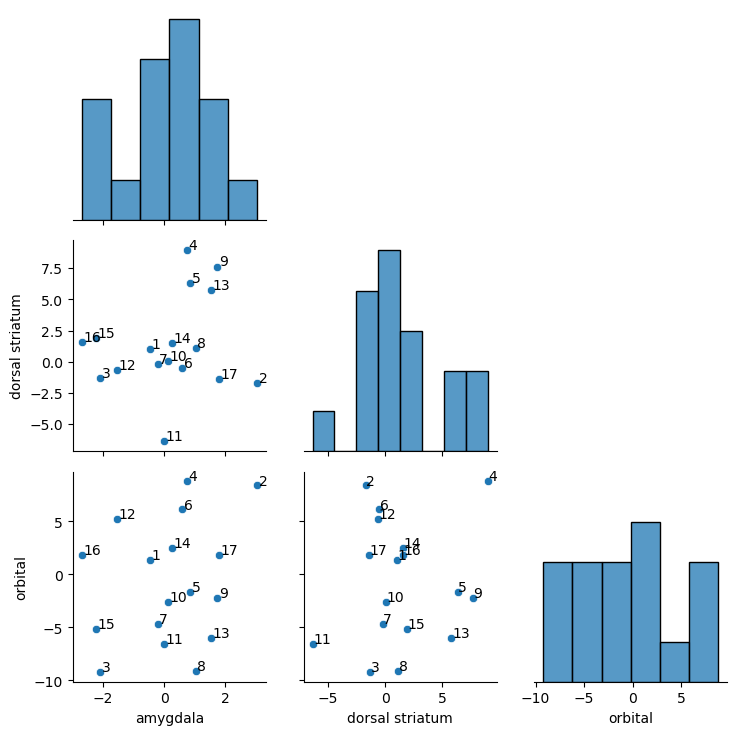

In [1243]:
g = sns.PairGrid(region_scores_df[['amygdala','dorsal striatum','orbital']], corner=True)
g.map_diag(sns.histplot)
g.map_offdiag(sns.scatterplot)

rows = ['dorsal striatum','orbital']
columns = ['amygdala','dorsal striatum']

for i in range(3):
    for j in range(3):
        if j<i:
            continue
        if i!= j:
            ax = g.axes[j,i]
            texts = []
            for k,r in region_scores_df.iterrows():
                texts.append(ax.text(r[columns[i]]+0.05,r[rows[j-1]]+0.05,r.name))
            #adjust_text(texts)

# search pca coefficients for circuits of interest

In [1197]:
pca_region_scores = np.zeros((pca_comp_df.shape[1],corr2_ms[1].shape[0]))
pca_region_scores_df = pd.DataFrame(pca_region_scores,columns=cols,index=range(1,pca_comp_df.shape[1]+1))

In [1198]:
for p in range(1,pca_comp_df.shape[1]+1):
    for i,r in enumerate(cols):
        idxs = pca_comp_df.index.str.contains(r)
        pca_region_scores_df.loc[p,r] = pca_comp_df.loc[idxs][p].sum()
    pca_region_scores_df.loc[p,'amygdala'] = pca_region_scores_df.loc[p,'Amygdala_L'] + pca_region_scores_df.loc[p,'Amygdala_R']
    pca_region_scores_df.loc[p,'dorsal striatum'] = pca_region_scores_df.loc[p,'Caudate_L'] + pca_region_scores_df.loc[p,'Caudate_R'] +pca_region_scores_df.loc[p,'Putamen_L'] + pca_region_scores_df.loc[p,'Putamen_R'] +pca_region_scores_df.loc[p,'Pallidum_L'] + pca_region_scores_df.loc[p,'Pallidum_R']
    #pca_region_scores_df.loc[p,'dorsal striatum'] = pca_region_scores_df.loc[p,'dorsal striatum'] / 3
    pca_region_scores_df.loc[p,'orbital'] = pca_region_scores_df.loc[p,'Frontal_Sup_Orb_L'] + pca_region_scores_df.loc[p,'Frontal_Sup_Orb_R'] +pca_region_scores_df.loc[p,'Frontal_Mid_Orb_L'] + pca_region_scores_df.loc[p,'Frontal_Mid_Orb_R'] +pca_region_scores_df.loc[p,'Frontal_Inf_Orb_L'] + pca_region_scores_df.loc[p,'Frontal_Inf_Orb_R'] +pca_region_scores_df.loc[p,'Frontal_Med_Orb_L'] + pca_region_scores_df.loc[p,'Frontal_Med_Orb_R']
    #pca_region_scores_df.loc[p,'orbital'] = pca_region_scores_df.loc[p,'orbital'] / 4

In [1199]:
pca_region_scores_df[['amygdala','dorsal striatum','orbital']]

,amygdala,dorsal striatum,orbital
1,0.313726,0.100627,0.176266
2,-0.122652,0.062886,-2.418998
3,0.164224,0.653648,-1.496936
4,-0.596485,0.350034,0.305576
5,0.230722,-1.062721,-0.798451
6,-0.885425,-1.406506,-1.679817
7,0.307785,-1.198004,0.328652
8,-0.109629,1.875814,0.732360
9,0.110665,2.330728,-0.138757
10,0.577642,0.490839,1.706526


In [1200]:
pca_region_scores_df[['amygdala','dorsal striatum','orbital']].sort_values("amygdala",ascending=False)

,amygdala,dorsal striatum,orbital
10,0.577642,0.490839,1.706526
1,0.313726,0.100627,0.176266
7,0.307785,-1.198004,0.328652
11,0.271548,0.228786,-1.579563
16,0.234266,0.604126,0.772887
5,0.230722,-1.062721,-0.798451
15,0.167355,0.042977,-0.545841
3,0.164224,0.653648,-1.496936
9,0.110665,2.330728,-0.138757
17,0.100359,0.061612,1.906393


In [1201]:
pca_region_scores_df[['amygdala','dorsal striatum','orbital']].sort_values("dorsal striatum",ascending=False)

,amygdala,dorsal striatum,orbital
9,0.110665,2.330728,-0.138757
8,-0.109629,1.875814,0.732360
3,0.164224,0.653648,-1.496936
16,0.234266,0.604126,0.772887
10,0.577642,0.490839,1.706526
4,-0.596485,0.350034,0.305576
11,0.271548,0.228786,-1.579563
13,0.028075,0.226593,1.740135
1,0.313726,0.100627,0.176266
2,-0.122652,0.062886,-2.418998


In [1202]:
pca_region_scores_df[['amygdala','dorsal striatum','orbital']].sort_values("orbital",ascending=False)

,amygdala,dorsal striatum,orbital
17,0.100359,0.061612,1.906393
13,0.028075,0.226593,1.740135
10,0.577642,0.490839,1.706526
16,0.234266,0.604126,0.772887
8,-0.109629,1.875814,0.732360
7,0.307785,-1.198004,0.328652
4,-0.596485,0.350034,0.305576
14,-0.104279,-0.176098,0.216609
1,0.313726,0.100627,0.176266
9,0.110665,2.330728,-0.138757


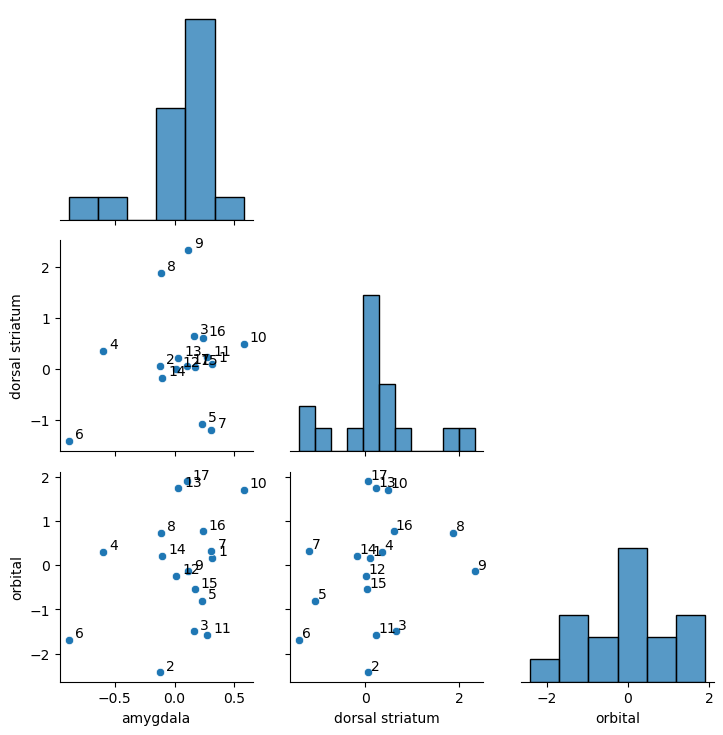

In [1203]:
g = sns.PairGrid(pca_region_scores_df[['amygdala','dorsal striatum','orbital']], corner=True)
g.map_diag(sns.histplot)
g.map_offdiag(sns.scatterplot)

rows = ['dorsal striatum','orbital']
columns = ['amygdala','dorsal striatum']

for i in range(3):
    for j in range(3):
        if j<i:
            continue
        if i!= j:
            ax = g.axes[j,i]
            texts = []
            for k,r in pca_region_scores_df.iterrows():
                texts.append(ax.text(r[columns[i]]+0.05,r[rows[j-1]]+0.05,r.name))
            #adjust_text(texts)

# random lin alg

In [53]:
np.linalg.eig(corr_ms[7])

EigResult(eigenvalues=array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.]), eigenvectors=array([[ 0.00000000e+000,  0.00000000e+000,  0.00000000e+000, ...,
         0.00000000e+000,  0.00000000e+000,  0.00000000e+000],
       [ 0.00000000e+000,  0.00000000e+000,  0.00000000e+000, ...,
         0.00000000e+000,  0.00000000e+000,  0.00000000e+000],
       [ 0.00000000e+000,  0.00000000e+000,  0.00000000e+000, ...,
         0.00000000e+000,  0.00000000e+000,  0.00000000e+000],
       ...,
       [ 0.00000000e+000,  0.00000000e+000,  0.00000000e+000, ...,
        -0.00000000e+000,  0.00000000e+000,  0.00000000e+000],
       [ 0.00000000e+000,  3.

In [57]:
for q in questions:
    print(f"{q}: {np.linalg.matrix_rank(corr_ms[q])}")

3: 88
7: 88
10: 88


In [62]:
nilpotency = {}
for q in questions:
    nilpotency[q] = []
    for k in range(corr_ms[q].shape[0]):
         nilpotency[q].append(np.linalg.matrix_rank(np.linalg.matrix_power(corr_ms[q],k)))

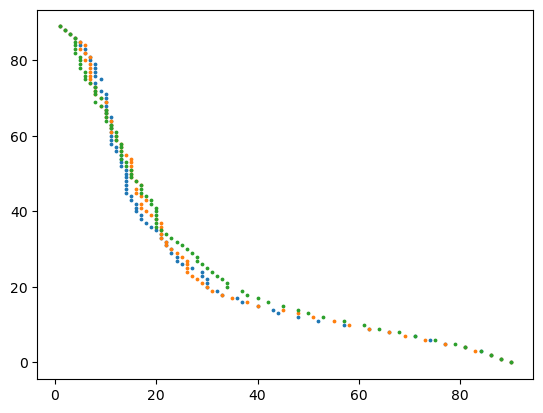

In [65]:
power = list(range(corr_ms[q].shape[0]))
for q in questions:
    plt.scatter(nilpotency[q],power,s=3)